# Assignment 4 — reviewed, reproducible 27-step notebook

- Uses your **existing** `MyDrive/RAG_Assignment3/` artifacts; does **not** rebuild them when present.
- Runs in a **separate** folder `MyDrive/RAG_Assignment4_BENCHMARK_V2/`, leaving prior logs untouched.
- Corrects deterministic retrieval, dev/test separation, judge labels, statistical tests, manual reviews, and reproducibility packaging.

**Control correction:** five mutually disjoint spans are selected from the ORIGINAL highest-ranked paper, based on the frozen full text, instead of requiring five non-adjacent overlapping index chunks. Exact passages are logged and used for citation scoring.


## Step 1 — Mount Drive and install compatible libraries

Edit `MOODLE_UPLOAD_TIME`, `KEYPOINTS_VERIFIED`, and `BENCHMARK_DEVIATION_APPROVED` in the next cell **only based on actual evidence**, not guesses. They are used as safety gates **before the final 160 test generations**. Empty values are allowed for preparatory Steps 1–14.

`BENCHMARK_DEVIATION_APPROVED` indicates the instructor confirmed/approved the **post-freeze seven-key-point revision** and control-source-span adjustment. Team review alone is not instructor approval. Preserve the original benchmark, document both SHA-256 values and never reuse old result logs.

`ALLOW_CORPUS_REBUILD` defaults to False; if one of the frozen corpus files is missing, the notebook stops instead of replacing the corpus silently. Rebuild only with explicit permission and a recorded protocol deviation.


In [1]:
# Step 1: Mount Drive, install compatible dependencies, record confirmations
from google.colab import drive
drive.mount('/content/drive')

%pip -q install 'arxiv>=2' 'pymupdf>=1.24' 'faiss-cpu>=1.8' 'sentence-transformers>=3,<5' 'rank-bm25>=0.2' 'statsmodels>=0.14' 'transformers>=4.45,<5' 'accelerate>=0.26' 'scipy>=1.11' 'scikit-learn>=1.3'

import os, json, hashlib, platform, subprocess, sys, time, re, gc, random
from datetime import datetime, timezone
import numpy as np, pandas as pd, torch

# ALWAYS keep old Assignment 3 data unchanged unless explicitly rebuilding.
base_dir = os.environ.get('RAG_A3_DATA_DIR','/content/drive/MyDrive/RAG_Assignment3')
run_dir = os.environ.get('RAG_A4_RUN_DIR','/content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2')
pdf_dir = os.path.join(base_dir,'rag_papers')
CONFIG_SOURCE_DIR=os.environ.get('RAG_A4_CONFIG_SOURCE',run_dir)
REPRODUCTION_MODE=os.environ.get('RAG_A4_REPRODUCE','0')=='1'
if REPRODUCTION_MODE and os.path.abspath(CONFIG_SOURCE_DIR)==os.path.abspath(run_dir):
    raise RuntimeError('For independent reproduction, use a different RAG_A4_RUN_DIR.')

# Replace ONLY with real facts, and only AFTER they have happened:
MOODLE_UPLOAD_TIME = ''               # e.g. 2026-10-27T15:30:00+05:00; MUST be actual Moodle timestamp
KEYPOINTS_VERIFIED = False           # True ONLY after all 100 key points have been genuinely checked
BENCHMARK_DEVIATION_APPROVED = False # True ONLY with actual instructor confirmation/approval of post-freeze edits
ALLOW_CORPUS_REBUILD = False         # Leave False for your existing 50 papers / 863 chunks

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

for d in (base_dir,run_dir,os.path.join(run_dir,'logs'),
          os.path.join(run_dir,'results'),os.path.join(run_dir,'figures'),
          os.path.join(run_dir,'manual'),os.path.join(run_dir,'data')):
    os.makedirs(d,exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU: Runtime → Change runtime type → T4 GPU')
print('GPU:',torch.cuda.get_device_name(0))
print('SOURCE folder:',base_dir)
print('NEW results folder:',run_dir)
print('Old output folders will not be used or overwritten.')


Mounted at /content/drive
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
GPU: Tesla T4
SOURCE folder: /content/drive/MyDrive/RAG_Assignment3
NEW results folder: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2
Old output folders will not be used or overwritten.


## Step 2 — Inventory and corpus protection

With your four existing files this must print `REBUILD_CORPUS = False`. If any source artifact is missing, this reviewed notebook **stops** until you restore it or explicitly approve the rebuild. It never silently changes the frozen dataset.


In [2]:
# Step 2: Inventory and protect frozen source artifacts

def file_sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1<<20),b''): h.update(block)
    return h.hexdigest()
sha256_file=file_sha256

NEEDED={
 'benchmark_questions.json':'original benchmark; DO NOT overwrite',
 'benchmark_questions_v2.json':'team-reviewed revised benchmark; required to run v2',
 'final_papers.json':'must remain frozen',
 'final_chunks.json':'must remain frozen',
 'final_faiss.index':'must remain frozen',
}
present={fn:os.path.isfile(os.path.join(base_dir,fn)) for fn in NEEDED}
for name,note in NEEDED.items():
    f=os.path.join(base_dir,name)
    print(('FOUND  ' if present[name] else 'MISSING'),name,
          f'{os.path.getsize(f)/1024:.1f} KB' if present[name] else '',note)
if not present['benchmark_questions.json']:
    raise FileNotFoundError('Original benchmark_questions.json missing; do not overwrite or recreate it.')
if not present['benchmark_questions_v2.json']:
    raise FileNotFoundError('Upload reviewed benchmark_questions_v2.json to MyDrive/RAG_Assignment3/ first. DO NOT rename the old file.')

REBUILD_PAPERS=not present['final_papers.json']
REBUILD_CHUNKS=REBUILD_PAPERS or not present['final_chunks.json']
REBUILD_INDEX=REBUILD_CHUNKS or not present['final_faiss.index']
REBUILD_CORPUS=REBUILD_PAPERS or REBUILD_CHUNKS or REBUILD_INDEX
print('\nREBUILD_CORPUS =',REBUILD_CORPUS)
if REBUILD_CORPUS and not ALLOW_CORPUS_REBUILD:
    raise RuntimeError('Frozen corpus artifact missing. NO AUTOMATIC REBUILD. Restore from Assignment 3, '
      'or get instructor approval and explicitly set ALLOW_CORPUS_REBUILD=True with a deviation record.')
if REBUILD_CORPUS:
    print('WARNING: rebuilding is a protocol deviation; save old backups and hashes.')
else:
    print('All frozen files present: steps 3–7 will load/skip without modifying the original corpus.')


FOUND   benchmark_questions.json 30.9 KB original benchmark; DO NOT overwrite
FOUND   benchmark_questions_v2.json 31.5 KB team-reviewed revised benchmark; required to run v2
FOUND   final_papers.json 2296.0 KB must remain frozen
FOUND   final_chunks.json 2925.9 KB must remain frozen
FOUND   final_faiss.index 1294.5 KB must remain frozen

REBUILD_CORPUS = False
All frozen files present: steps 3–7 will load/skip without modifying the original corpus.


# Part 1 — Corpus and index (steps 3–7)

These stages are skipped when Assignment 3 has all frozen artifacts. If something is missing, stages are rebuilt independently only after explicit approval. **Never rebuild to improve final results**.


## Step 3: Collect 50 papers from arXiv

In [3]:
# Step 3: arXiv metadata

if REBUILD_PAPERS:
    import arxiv
    client = arxiv.Client(page_size=20, delay_seconds=3, num_retries=3)
    QUERY = 'cat:cs.CL AND (RAG OR "retrieval augmented generation")'
    search = arxiv.Search(query=QUERY, max_results=50,
                          sort_by=arxiv.SortCriterion.Relevance)

    papers = []
    for r in client.results(search):
        pid = r.entry_id.split("/abs/")[-1]
        papers.append({
            "paper_id": pid,
            "title": r.title.strip().replace("\n", " "),
            "abstract": r.summary.strip().replace("\n", " "),
            "published": str(r.published.date()),
            "pdf_url": r.pdf_url,
        })
    papers_df = pd.DataFrame(papers).drop_duplicates("paper_id").reset_index(drop=True)
    print("collected:", len(papers_df), "unique papers")
    print("query:", QUERY)
    json.dump({"query": QUERY, "collected_at": datetime.now().isoformat(timespec="seconds"),
               "n": len(papers_df)},
              open(os.path.join(run_dir, "corpus_query.json"), "w"), indent=2)
    display(papers_df[["paper_id", "title", "published"]].head(10))
else:
    print("skipped, using the frozen corpus")


skipped, using the frozen corpus


## Step 4: Download the PDFs

In [4]:
# Step 4: PDFs

if REBUILD_PAPERS:
    os.makedirs(pdf_dir,exist_ok=True)
    import requests
    ok, failed = 0, []
    for i, row in papers_df.iterrows():
        fn = row["paper_id"].replace("/", "_") + ".pdf"
        fp = os.path.join(pdf_dir, fn)
        if os.path.exists(fp) and os.path.getsize(fp) > 10000:
            ok += 1; continue
        try:
            r = requests.get(row["pdf_url"], timeout=60)
            r.raise_for_status()
            open(fp, "wb").write(r.content); ok += 1
        except Exception as e:
            failed.append((row["paper_id"], str(e)[:60]))
        time.sleep(1.5)
        if (i + 1) % 10 == 0: print(f"  {i+1}/{len(papers_df)}")
    print("downloaded or already present:", ok, "| failed:", len(failed))
    for f in failed: print("  ", f)
else:
    print("skipped")


skipped


## Step 5: Extract text, remove the bibliography, keep the appendicesReference lists are full of topical keywords and are retrieved often whilecontaining no answerable content, so they are cut. Appendices are kept onpurpose, because that is where the experimental tables live and severalbenchmark questions ask about them.

In [5]:
# Step 5: Text extraction and cleaning

if REBUILD_PAPERS:
    import fitz   # PyMuPDF

    REF_HEAD = re.compile(r"(?im)^\s*(?:\d+\.?\s*)?(references|bibliography)\s*$")
    APP_HEAD = re.compile(r"(?im)^\s*(?:appendix(?:es)?|appendices|"
                          r"supplementary\s+(?:material|information))\b.*$")

    def clean(text):
        refs = list(REF_HEAD.finditer(text))
        if not refs: return text, 0
        cut = refs[-1].start()
        head = text[:cut]
        tail = text[cut:]
        app = APP_HEAD.search(tail)
        kept_app = tail[app.start():] if app else ""
        if len(head) < len(text) * 0.35:          # suspicious cut, keep everything
            return text, 0
        return head + ("\n\n" + kept_app if kept_app else ""), len(tail) - len(kept_app)

    rows, skipped = [], []
    for i, row in papers_df.iterrows():
        fp = os.path.join(pdf_dir, row["paper_id"].replace("/", "_") + ".pdf")
        if not os.path.exists(fp): skipped.append(row["paper_id"]); continue
        try:
            doc = fitz.open(fp)
            raw = "\n".join(p.get_text("text") for p in doc); doc.close()
        except Exception as e:
            skipped.append(row["paper_id"]); continue
        raw = (raw.replace("\ufb00", "ff").replace("\ufb01", "fi").replace("\ufb02", "fl"))
        raw = re.sub(r"-\n(\w)", r"\1", raw)
        raw = re.sub(r"\n{3,}", "\n\n", raw)
        txt, removed = clean(raw)
        if len(txt) < 3000: skipped.append(row["paper_id"]); continue
        rows.append({**row.to_dict(), "text": txt, "chars": len(txt),
                     "chars_removed": removed})

    final_papers_df = pd.DataFrame(rows)
    final_papers_df.to_json(os.path.join(base_dir, "final_papers.json"))
    print("papers with usable text:", len(final_papers_df), "| skipped:", len(skipped))
    print("median length:", int(final_papers_df["chars"].median()), "characters")
else:
    final_papers_df = pd.read_json(os.path.join(base_dir, "final_papers.json"))
    print("loaded", len(final_papers_df), "papers from Drive")


loaded 50 papers from Drive


## Step 6: Split into passages

In [6]:
# Step 6: Chunking, 500 words with a 100 word overlap

CHUNK_SIZE, CHUNK_OVERLAP = 500, 100

if REBUILD_CHUNKS:
    def split_words(text, size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
        w = text.split(); step = size - overlap
        return [" ".join(w[i:i+size]) for i in range(0, len(w), step) if w[i:i+size]]

    chunks = []
    for _, p in final_papers_df.iterrows():
        for j, c in enumerate(split_words(p["text"])):
            if len(c.split()) < 50: continue
            chunks.append({"chunk_id": f"{p['paper_id']}_final_{j}",
                           "paper_id": p["paper_id"], "title": p["title"],
                           "chunk_index": j, "text": c, "word_count": len(c.split())})
    final_chunks_df = pd.DataFrame(chunks)
    final_chunks_df.to_json(os.path.join(base_dir, "final_chunks.json"))
    print("passages:", len(final_chunks_df))
else:
    final_chunks_df = pd.read_json(os.path.join(base_dir, "final_chunks.json"))
    print("loaded", len(final_chunks_df), "passages from Drive")

print("median passage length:", int(final_chunks_df["word_count"].median()), "words")


loaded 863 passages from Drive
median passage length: 500 words


## Step 7: Embed and build the vector index

In [7]:
# Step 7: Embeddings and FAISS

import faiss
from sentence_transformers import SentenceTransformer

if REBUILD_INDEX:
    emb0 = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    vecs = emb0.encode(final_chunks_df["text"].tolist(), normalize_embeddings=True,
                       convert_to_numpy=True, batch_size=64,
                       show_progress_bar=True).astype("float32")
    final_index = faiss.IndexFlatIP(vecs.shape[1]); final_index.add(vecs)
    faiss.write_index(final_index, os.path.join(base_dir, "final_faiss.index"))
    print("index built:", final_index.ntotal, "vectors of", vecs.shape[1], "dimensions")
else:
    final_index = faiss.read_index(os.path.join(base_dir, "final_faiss.index"))
    print("index loaded:", final_index.ntotal, "vectors")

assert len(final_chunks_df) == final_index.ntotal, "index and passages disagree"
print("index and passages agree:", final_index.ntotal)


index loaded: 863 vectors
index and passages agree: 863


# Part 2. Benchmark and protocol freeze

## Step 8 — Load and validate benchmark structure

This run uses the reviewed `benchmark_questions_v2.json` with seven key-point revisions. The old original remains preserved. Step 8 validates the exact expected file hash; team review and instructor approval/confirmation must be documented before Step 15.


In [8]:
# Step 8: Load & structurally validate the real benchmark (NO synthetic reconstruction)
import faiss
PAPERS_FILE=os.path.join(base_dir,'final_papers.json')
CHUNKS_FILE=os.path.join(base_dir,'final_chunks.json')
ORIGINAL_INDEX_FILE=os.path.join(base_dir,'final_faiss.index')
BENCHMARK_FILE=os.path.join(base_dir,'benchmark_questions_v2.json')
EXPECTED_BENCHMARK_SHA256='2e62cd61ece5d17cb0e3213bfe4194a514881681880c12a6bc4dd2f6e70a733d'
assert file_sha256(BENCHMARK_FILE)==EXPECTED_BENCHMARK_SHA256, ('Revised benchmark hash differs from the team-reviewed version: stop and investigate.')
assert len(final_papers_df)==50, 'Protocol freezes 50 papers; report any change before final experiments'
assert len(final_chunks_df)==863, 'Protocol freezes 863 chunks; report any change before final experiments'
assert final_index.ntotal==len(final_chunks_df), 'FAISS and chunks do not match'
raw_benchmark=json.load(open(BENCHMARK_FILE,encoding='utf-8'))
if isinstance(raw_benchmark,dict):
    raw_benchmark=raw_benchmark.get('questions',raw_benchmark.get('benchmark'))
if not isinstance(raw_benchmark,list):
    raise ValueError('Benchmark must be a JSON list of questions, or a dict containing questions list')

def normalise_question(e):
    a=e.get('answerable',True)
    if isinstance(a,str): a=a.strip().lower() in ('true','yes','1')
    return {'question_id':e.get('question_id') or e.get('id'),
            'question':e.get('question'), 'answerable':bool(a),
            'question_type':e.get('question_type','unspecified'),
            'reference_answer':e.get('reference_answer') or e.get('answer') or '',
            'key_points':e.get('key_points',[]) or [],
            'supporting_papers':e.get('supporting_papers',[]) or [],
            'supporting_chunks':e.get('supporting_chunks',[]) or []}
benchmark=sorted([normalise_question(e) for e in raw_benchmark],key=lambda q:q['question_id'])
ids=[q['question_id'] for q in benchmark]
assert len(ids)==25 and len(set(ids))==25,'Expected exactly 25 unique questions'
assert sum(q['answerable'] for q in benchmark)==20,'Expected 20 answerable and 5 unanswerable'
assert all(len(q['key_points'])==5 for q in benchmark if q['answerable'])
assert sum(len(q['key_points']) for q in benchmark)==100,'Expected 100 key points overall'
assert all(q['question'] and (q['reference_answer'] if q['answerable'] else True) for q in benchmark), 'Incomplete question/reference'
known_chunks=set(final_chunks_df['chunk_id'].astype(str))
missing={q['question_id']:[c for c in q['supporting_chunks'] if str(c) not in known_chunks]
        for q in benchmark if q['answerable']}
missing={key:vals for key,vals in missing.items() if vals}
assert not missing,f'Missing evidence chunk identifiers: {missing}'
print('Benchmark: 25 questions (20 answerable, 5 unanswerable), 100 points')
print('Actual benchmark file: benchmark_questions_v2.json')
print('SHA256:',file_sha256(BENCHMARK_FILE))
print('CAUTION: Content revision after Appendix A freeze must be disclosed/approved before Step 15.')
print('Structural checks ≠ content validation: all 100 key points still require evidence review.')


Benchmark: 25 questions (20 answerable, 5 unanswerable), 100 points
Actual benchmark file: benchmark_questions_v2.json
SHA256: 2e62cd61ece5d17cb0e3213bfe4194a514881681880c12a6bc4dd2f6e70a733d
CAUTION: Content revision after Appendix A freeze must be disclosed/approved before Step 15.
Structural checks ≠ content validation: all 100 key points still require evidence review.


## Step 9 — Record hashes and DEV/TEST split

DEV: Q01, Q09, Q16, Q19, Q21. TEST: remaining 20 questions. This technical record does **not** prove a Moodle upload occurred before the experimental run.


In [9]:
# Step 9: Record source hashes and frozen DEV/TEST identifiers
DEV_IDS = ['Q01', 'Q09', 'Q16', 'Q19', 'Q21']
TEST_IDS = [q['question_id'] for q in benchmark if q['question_id'] not in DEV_IDS]
dev = [q for q in benchmark if q['question_id'] in DEV_IDS]
# Do not inspect test content or compute test prompts before final configuration.
# The test records remain in memory but are not used by development code.
assert len(dev) == 5 and len(TEST_IDS) == 20
assert sum(q['answerable'] for q in dev) == 4
assert sum(not q['answerable'] for q in dev) == 1

freeze = {
    'record_created_utc': datetime.now(timezone.utc).isoformat(),
    'benchmark_file': os.path.basename(BENCHMARK_FILE),
    'benchmark_sha256': file_sha256(BENCHMARK_FILE),
    'papers_sha256': file_sha256(PAPERS_FILE),
    'chunks_sha256': file_sha256(CHUNKS_FILE),
    'original_index_sha256': file_sha256(ORIGINAL_INDEX_FILE),
    'n_papers': len(final_papers_df), 'n_chunks': len(final_chunks_df),
    'n_questions': len(benchmark), 'dev_ids': DEV_IDS, 'test_ids': TEST_IDS,
    'n_test_answerable': 16, 'n_test_unanswerable': 4,
    'primary_metric': 'completeness',
    'secondary_metrics': ['hallucination_rate','accuracy','false_abstention_rate',
                          'correct_abstention_rate','gold_paper_recall','input_tokens',
                          'latency_sec'],
    'conditions': ['no_retrieval','random5','bm25_5','k1','k3','k5','k10','control'],
    'seed': SEED, 'do_sample': False, 'max_new_tokens': 512,
    'passages_per_paper': 1, 'passage_cap_tokens': 550,
    'bootstrap_resamples': 10000, 'alpha': 0.05,
    'signed_protocol_is_external': True,
    'source_benchmark_filename': os.path.basename(BENCHMARK_FILE),
    'appendix_a_declared_benchmark': 'benchmark_questions_v2.json',
    'protocol_filename_discrepancy_requires_approval': True,
}
freeze_path = os.path.join(run_dir, 'protocol_freeze.json')
if os.path.exists(freeze_path):
    previous = json.load(open(freeze_path, encoding='utf-8'))
    for key in ('benchmark_sha256','chunks_sha256','original_index_sha256',
                'dev_ids','test_ids','conditions','seed'):
        assert previous.get(key) == freeze[key], f'FROZEN PROTOCOL MISMATCH: {key}'
    freeze = previous
else:
    # This is a machine-readable *record* of Appendix A, not evidence of Moodle upload.
    with open(freeze_path, 'w', encoding='utf-8') as f:
        json.dump(freeze, f, ensure_ascii=False, indent=2)

if REPRODUCTION_MODE:
    original_freeze = os.path.join(CONFIG_SOURCE_DIR, 'protocol_freeze.json')
    assert os.path.isfile(original_freeze), 'Original machine-readable freeze is required'
    historical = json.load(open(original_freeze, encoding='utf-8'))
    for key in ('benchmark_sha256', 'chunks_sha256', 'test_ids', 'conditions'):
        assert historical[key] == freeze[key], f'Source freeze differs: {key}'

print('Dev IDs:', DEV_IDS)
print('Test IDs (identifiers only):', TEST_IDS)
print('Frozen benchmark SHA256:', freeze['benchmark_sha256'])
print('Moodle evidence is a separate timestamp / receipt, not this JSON file.')


Dev IDs: ['Q01', 'Q09', 'Q16', 'Q19', 'Q21']
Test IDs (identifiers only): ['Q02', 'Q03', 'Q04', 'Q05', 'Q06', 'Q07', 'Q08', 'Q10', 'Q11', 'Q12', 'Q13', 'Q14', 'Q15', 'Q17', 'Q18', 'Q20', 'Q22', 'Q23', 'Q24', 'Q25']
Frozen benchmark SHA256: 2e62cd61ece5d17cb0e3213bfe4194a514881681880c12a6bc4dd2f6e70a733d
Moodle evidence is a separate timestamp / receipt, not this JSON file.


# Part 3. RetrieversFour ways of filling the prompt plus the control, all returning the same kind ofobject so that nothing downstream changes between conditions. That is what makesthe comparison fair.
The `control` condition uses the same top-ranked paper, but creates five **non-overlapping token spans** of its frozen full text instead of relying on overlapping indexed chunks. The selected spans are reranked with the frozen dense embedding model. These virtual spans and their provenance are saved in generation logs; the full text corpus and original FAISS index are unchanged. This is a documented control-implementation clarification; describe it in deviations/limitations and obtain approval if the frozen protocol is interpreted more narrowly.


In [10]:
# Step 10: Deterministic dense, BM25, random and control retrievers
import re, random, hashlib
from rank_bm25 import BM25Okapi
import numpy as np

CHUNKS = final_chunks_df.to_dict('records')
CHUNK_BY_ID = {str(c['chunk_id']): c for c in CHUNKS}
assert len(CHUNK_BY_ID) == len(CHUNKS), 'Duplicate chunk identifiers'
assert all('paper_id' in c and 'text' in c and 'chunk_index' in c for c in CHUNKS)
PAPER_IDS = sorted({str(c['paper_id']) for c in CHUNKS})
assert len(PAPER_IDS) == 50
PAPER_CHUNKS = {p: [c for c in CHUNKS if str(c['paper_id']) == p]
                for p in PAPER_IDS}

word_tokenise = lambda s: re.findall(r'[a-z0-9]+', str(s).lower())
bm25 = BM25Okapi([word_tokenise(c['text']) for c in CHUNKS])

def dense_rank(question, embedder, index):
    v = embedder.encode([question], normalize_embeddings=True,
                        convert_to_numpy=True).astype('float32')
    scores, locations = index.search(v, index.ntotal)
    return [{**CHUNKS[int(i)], 'score': float(s)} for s, i
            in zip(scores[0], locations[0]) if int(i) >= 0]

def top_distinct_papers(ranked, k, per_paper=1):
    order = []
    for r in ranked:
        p = str(r['paper_id'])
        if p not in order:
            order.append(p)
        if len(order) == k:
            break
    if len(order) != k:
        raise ValueError(f'Retriever returned {len(order)} unique papers, expected {k}')
    return [r for p in order for r in [x for x in ranked if str(x['paper_id']) == p][:per_paper]]

def retrieve_dense(question, k, embedder, index):
    return top_distinct_papers(dense_rank(question, embedder, index), k)

CONTROL_ALGORITHM = 'top_ranked_paper_disjoint_token_windows_v1'

# The source article remains the TOP ranked paper. The 500-word Assignment 3
# index chunks overlap by 100 words; some papers cannot supply five disjoint
# indexed chunks. We create five source spans from the frozen full article text
# instead. The original PDFs, corpus JSON and FAISS indexes NEVER change.
# The virtual passage text must be saved in each generation record so the
# citation judge evaluates the passage the generator actually saw.
_PAPER_RECORDS = {str(p['paper_id']): p for p in final_papers_df.to_dict('records')}

def retrieve_control(question, embedder, index, n_chunks=5):
    if 'tokenizer' not in globals():
        raise RuntimeError('Load the generator tokenizer (Step 11) first')
    ranked = dense_rank(question, embedder, index)
    top = str(ranked[0]['paper_id'])
    if top not in _PAPER_RECORDS:
        raise ValueError(f'Top-ranked paper absent from frozen text: {top}')
    source = _PAPER_RECORDS[top]
    # Token-based source spans are strictly disjoint. MAX 550 tokens/window,
    # matching the evidence cap in the rest of the experiment.
    all_ids = tokenizer.encode(str(source['text']), add_special_tokens=False)
    total = len(all_ids)
    if total < n_chunks * 200:
        raise ValueError(f'CONTROL_SOURCE_TOO_SHORT: top paper {top} only has '
                         f'{total} tokens; cannot fairly form 5 passages.')
    span_len = min(PASSAGE_TOKEN_CAP, total // n_chunks)
    if span_len < 200:
        raise ValueError(f'CONTROL_SOURCE_TOO_SHORT: top paper {top} '
                         f'has fewer than 5x200 tokens.')
    spans = []
    for start in range(0, total - span_len + 1, span_len):
        end = start + span_len
        snippet = tokenizer.decode(all_ids[start:end], skip_special_tokens=True)
        if not snippet.strip():
            continue
        spans.append(dict(
            chunk_id=f'{top}_control_tokens_{start}_{end}', paper_id=top,
            title=str(source.get('title', top)), chunk_index=start // span_len,
            text=snippet, source_token_start=start, source_token_end=end,
            control_virtual=True))
    if len(spans) < n_chunks:
        raise ValueError(f'CONTROL_NOT_AVAILABLE: top paper {top} yielded '
                         f'{len(spans)} disjoint passages (expected {n_chunks})')

    # Same selected dense embedding model, applied to mutually disjoint spans
    # from the same TOP paper. No test-dependent settings or substitutions.
    passage_emb = embedder.encode([s['text'] for s in spans],
                                  normalize_embeddings=True,
                                  convert_to_numpy=True).astype('float32')
    query_emb = embedder.encode([question], normalize_embeddings=True,
                                convert_to_numpy=True).astype('float32')[0]
    scores = passage_emb @ query_emb
    order = np.argsort(-scores, kind='stable')[:n_chunks]
    selected = []
    for i in order:
        r = dict(spans[int(i)])
        r['score'] = float(scores[int(i)])
        selected.append(r)
    ranges = sorted((s['source_token_start'],s['source_token_end'])
                    for s in selected)
    assert len(selected) == n_chunks and len({s['paper_id'] for s in selected}) == 1
    assert all(ranges[i][1] <= ranges[i+1][0] for i in range(len(ranges)-1))
    return selected

def retrieve_bm25(question, k=5):
    scores = bm25.get_scores(word_tokenise(question))
    order = np.argsort(-scores, kind='stable')
    ranked = [{**CHUNKS[int(i)], 'score': float(scores[int(i)])} for i in order]
    return top_distinct_papers(ranked, k)

def stable_seed(question, seed=SEED):
    q_hash = hashlib.sha256(question.encode('utf-8')).digest()
    return seed + int.from_bytes(q_hash[:8], 'big')

def retrieve_random(question, k=5):
    rng = random.Random(stable_seed(question))
    papers = rng.sample(PAPER_IDS, k)
    return [{**rng.choice(PAPER_CHUNKS[pid]), 'score': 0.0} for pid in papers]

def retrieve_none(question):
    return []

# Offline-reasonable assertions: Python's process-randomised hash() is NEVER used.
assert [x['chunk_id'] for x in retrieve_random('test question')] == [
       x['chunk_id'] for x in retrieve_random('test question')]
print('Dense, control, BM25, RANDOM-5 and no-retrieval are defined.')


Dense, control, BM25, RANDOM-5 and no-retrieval are defined.


# Part 4. Generator and the decisions made on the development set

## Step 11: Load the generator

In [11]:
# Step 11: Generator and the prompts (no TEST access)
import torch, time, re
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = 'Qwen/Qwen2.5-1.5B-Instruct'
MAX_NEW_TOKENS, PASSAGE_TOKEN_CAP, TOKEN_CEILING = 512, 550, 8192

PROMPT_A = (
    'You are a scientific research assistant. '
    'Answer only using the supplied evidence. '
    'Cite the sources supporting each claim as [Source 1], [Source 2]. '
    'If the evidence does not contain the answer, reply exactly: '
    'INSUFFICIENT EVIDENCE. Do not invent facts, numbers or citations.'
)
PROMPT_B = (
    'You are a scientific research assistant. Answer the question using only '
    'the supplied evidence, and cite the source of each claim as [Source 1], '
    '[Source 2]. Partial evidence is still evidence: if the passages support '
    'part of the answer, give that part and say which part is missing. '
    'Reply with exactly INSUFFICIENT EVIDENCE only when none of the passages '
    'is relevant to the question. Do not invent facts, numbers or citations.'
)
# No-retrieval must be genuinely closed-book, not forced to abstain by the
# evidence-only RAG instructions. This contrast is documented as a clarification.
NO_RETRIEVAL_PROMPT = (
    'You are a scientific research assistant answering from your existing '
    'knowledge only. No retrieval passages are available. Answer the question '
    'as accurately as possible, acknowledge uncertainty, and do not invent '
    'facts, numerical results, or source citations. If you cannot answer, '
    'reply exactly: INSUFFICIENT EVIDENCE.'
)

tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME, torch_dtype=torch.float16, device_map='auto').eval()

def cap_passage(text):
    token_ids = tokenizer.encode(str(text), add_special_tokens=False)
    return tokenizer.decode(token_ids[:PASSAGE_TOKEN_CAP], skip_special_tokens=True)

def build_prompt(question, evidence, system_prompt):
    if evidence:
        context = '\n\n'.join(
            f"[Source {i}] {e.get('title', e['paper_id'])}\n{cap_passage(e['text'])}"
            for i, e in enumerate(evidence, 1))
    else:
        context = '(no retrieval passages available)'
    messages = [dict(role='system', content=system_prompt),
                dict(role='user', content=f'Question: {question}\n\nEvidence:\n{context}')]
    return tokenizer.apply_chat_template(messages, tokenize=False,
                                         add_generation_prompt=True)

def exact_abstention(answer):
    return bool(re.fullmatch(r'\s*INSUFFICIENT\s+EVIDENCE\s*[.!]?\s*',
                             str(answer), flags=re.IGNORECASE))

@torch.inference_mode()
def generate(prompt):
    encoded = tokenizer(prompt, return_tensors='pt', truncation=False)
    n_in = int(encoded['input_ids'].shape[1])
    if n_in + MAX_NEW_TOKENS > TOKEN_CEILING:
        raise ValueError(f'TOKEN_BUDGET_EXCEEDED: {n_in}+{MAX_NEW_TOKENS} '
                         f'> {TOKEN_CEILING} (do not trim context selectively)')
    encoded = encoded.to(next(llm.parameters()).device)
    torch.manual_seed(SEED)
    torch.cuda.synchronize()
    start = time.perf_counter()
    out = llm.generate(**encoded, max_new_tokens=MAX_NEW_TOKENS,
                       do_sample=False, use_cache=True,
                       pad_token_id=tokenizer.eos_token_id)
    torch.cuda.synchronize()
    latency = time.perf_counter() - start
    ids = out[0][n_in:]
    return dict(answer=tokenizer.decode(ids, skip_special_tokens=True).strip(),
                input_tokens=n_in, output_tokens=len(ids),
                stop_reason='length' if len(ids) >= MAX_NEW_TOKENS else 'eos',
                latency_sec=round(latency, 3))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## Step 12: DEVELOPMENT ONLY. Choose the embedding modelThe Assignment 3 pilot reached gold-paper recall of only 0.708 at k = 10, whichbounds every measure that follows. Appendix A left this decision open and saidit would be made on the development set. This cell makes it there and nowhereelse.

In [12]:
# Step 12: Select embedding model using DEV recall at k=5 only
from sentence_transformers import SentenceTransformer
import faiss, numpy as np, pandas as pd

CANDIDATES = {
    'all-MiniLM-L6-v2': 'sentence-transformers/all-MiniLM-L6-v2',
    'bge-small-en-v1.5': 'BAAI/bge-small-en-v1.5',
}
QUERY_PREFIX = {
    'all-MiniLM-L6-v2': '',
    'bge-small-en-v1.5': 'Represent this sentence for searching relevant passages: ',
}

def build_index(model_name):
    embedder = SentenceTransformer(model_name)
    vectors = embedder.encode([c['text'] for c in CHUNKS],
                              normalize_embeddings=True, convert_to_numpy=True,
                              batch_size=64, show_progress_bar=True).astype('float32')
    index = faiss.IndexFlatIP(vectors.shape[1]); index.add(vectors)
    assert index.ntotal == len(CHUNKS)
    return embedder, index

if REPRODUCTION_MODE:
    print('Reproduction: skipping model selection. Step 14 loads the stored choice.')
else:
    dev_answerable = [q for q in dev if q['answerable']]
    assert len(dev_answerable) == 4
    dev_rows = []
    built = {}
    for short, model_name in CANDIDATES.items():
        emb, idx = build_index(model_name)
        built[short] = (emb, idx)
        for q in dev_answerable:
            gold = set(q['supporting_papers'])
            assert gold, f'Missing gold-paper identifiers: {q["question_id"]}'
            retrieved = retrieve_dense(QUERY_PREFIX[short] + q['question'],
                                       5, emb, idx)
            got = {r['paper_id'] for r in retrieved}
            dev_rows.append(dict(model=short, question_id=q['question_id'], k=5,
                                 gold_paper_recall=len(gold & got) / len(gold)))
    dev_retriever = pd.DataFrame(dev_rows)
    means = dev_retriever.groupby('model')['gold_paper_recall'].mean()
    CHOSEN = means.sort_values(ascending=False, kind='stable').index[0]
    print('Pre-registered comparison: DEV gold paper recall at k=5 only')
    print(means.round(4).to_string())
    print('Selected:', CHOSEN)
    dev_retriever.to_csv(os.path.join(run_dir, 'results', 'dev_retriever_selection.csv'),
                         index=False)
    emb_sel, idx_sel = built[CHOSEN]
    # Original selected index must be accessible to another student.
    selected_path = os.path.join(run_dir, 'selected_faiss.index')
    if not os.path.exists(selected_path):
        faiss.write_index(idx_sel, selected_path)
        print('Saved selected_faiss.index (not the obsolete A3 index).')
    else:
        # Never replace a frozen retrieval index during a repeat setup run.
        import tempfile
        with tempfile.NamedTemporaryFile(suffix='.index',delete=False) as tmp:
            temp_path=tmp.name
        try:
            faiss.write_index(idx_sel, temp_path)
            assert file_sha256(temp_path) == file_sha256(selected_path), (
                'Selected FAISS index would change; preserve original and document deviation.')
        finally:
            if os.path.exists(temp_path): os.unlink(temp_path)
        print('Existing frozen selected_faiss.index verified and preserved.')


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (15 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Pre-registered comparison: DEV gold paper recall at k=5 only
model
all-MiniLM-L6-v2     0.4583
bge-small-en-v1.5    0.8333
Selected: bge-small-en-v1.5
Existing frozen selected_faiss.index verified and preserved.


## Step 13: DEVELOPMENT ONLY. Choose the abstention wordingThe pilot produced five false abstentions in sixteen answerable generations,which removed conditions from the comparison. Two wordings are compared here, onthe development questions only.

In [13]:
# Step 13: Select abstention wording on DEV only

if REPRODUCTION_MODE:
    print('Reproduction: skipping DEV prompt-selection run; fixed system prompt '
          'comes from the archived config in Step 14.')
else:
    dev_answerable = [q for q in dev if q['answerable']]
    results_dev = []
    for label, prompt in [('A_original', PROMPT_A), ('B_revised', PROMPT_B)]:
        for q in dev_answerable:
            passages = retrieve_dense(QUERY_PREFIX[CHOSEN] + q['question'],
                                      5, emb_sel, idx_sel)
            g = generate(build_prompt(q['question'], passages, prompt))
            results_dev.append(dict(wording=label, question_id=q['question_id'],
                                    abstained=exact_abstention(g['answer']),
                                    output_tokens=g['output_tokens']))
            torch.cuda.empty_cache()
    dev_abs = pd.DataFrame(results_dev)
    summary = dev_abs.groupby('wording')['abstained'].agg(['sum','size','mean'])
    # Predeclared deterministic tie-break: prefer the original wording.
    SYSTEM_PROMPT = PROMPT_B if (
        summary.loc['B_revised', 'mean'] < summary.loc['A_original', 'mean']
    ) else PROMPT_A
    print('DEV false abstentions:'); print(summary.to_string())
    print('Selected:', 'B_revised' if SYSTEM_PROMPT == PROMPT_B else 'A_original')
    dev_abs.to_csv(os.path.join(run_dir, 'results', 'dev_abstention_selection.csv'),
                   index=False)


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


DEV false abstentions:
            sum  size  mean
wording                    
A_original    1     4  0.25
B_revised     0     4  0.00
Selected: B_revised


## Step 14 — Freeze configuration using DEVELOPMENT questions only

No TEST question is inspected here. The selected FAISS index and prompt hashes are pinned. In a reproduction run the archived choices must be loaded, not reselected.

The token audit must now pass for the control even when the top-ranked source has fewer than five disjoint overlapping-index chunks, provided its frozen full article text can form five meaningful disjoint spans.


In [14]:
# Step 14: Lock final configuration; token audit on DEV only
import json, hashlib, os, faiss

config_path = os.path.join(run_dir, 'final_config.json')
if REPRODUCTION_MODE:
    archived_path = os.path.join(CONFIG_SOURCE_DIR, 'final_config.json')
    assert os.path.isfile(archived_path), 'Archived final_config.json required'
    CONFIG = json.load(open(archived_path, encoding='utf-8'))
    # Never select or modify hyperparameters during reproduction.
    assert CONFIG['benchmark_sha256'] == freeze['benchmark_sha256']
    assert CONFIG['chunks_sha256'] == freeze['chunks_sha256']
    CHOSEN = CONFIG['retriever_short']
    SYSTEM_PROMPT = CONFIG['system_prompt']
    NO_RETRIEVAL_PROMPT = CONFIG['no_retrieval_prompt']
    assert CHOSEN in CANDIDATES and CONFIG['retriever'] == CANDIDATES[CHOSEN]
    selected_index_path = os.path.join(CONFIG_SOURCE_DIR, 'selected_faiss.index')
    assert os.path.isfile(selected_index_path), 'Selected FAISS index required'
    assert file_sha256(selected_index_path) == CONFIG['selected_index_sha256']
    emb_sel = SentenceTransformer(CONFIG['retriever'])
    idx_sel = faiss.read_index(selected_index_path)
    assert idx_sel.ntotal == len(CHUNKS)
    with open(config_path, 'w') as f: json.dump(CONFIG, f, indent=2)
else:
    selected_index_path = os.path.join(run_dir, 'selected_faiss.index')
    CONFIG = dict(
        retriever=CANDIDATES[CHOSEN], retriever_short=CHOSEN,
        query_prefix=QUERY_PREFIX[CHOSEN], generator=LLM_NAME,
        system_prompt=SYSTEM_PROMPT,
        system_prompt_sha256=hashlib.sha256(SYSTEM_PROMPT.encode()).hexdigest(),
        no_retrieval_prompt=NO_RETRIEVAL_PROMPT,
        judge='microsoft/Phi-3.5-mini-instruct',
        max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
        passage_token_cap=PASSAGE_TOKEN_CAP, chunks_per_paper=1,
        control_chunks=5, control_algorithm=CONTROL_ALGORITHM,
        control_span_max_tokens=PASSAGE_TOKEN_CAP,
        token_ceiling=TOKEN_CEILING, seed=SEED,
        conditions=freeze['conditions'],
        benchmark_sha256=freeze['benchmark_sha256'],
        chunks_sha256=freeze['chunks_sha256'],
        selected_index_sha256=file_sha256(selected_index_path))
    # Never silently overwrite a previously locked configuration.
    if os.path.exists(config_path):
        old = json.load(open(config_path, encoding='utf-8'))
        assert old == CONFIG, ('Existing config differs. Archive the old run and '
                               'document any deviations; do not silently retune.')
    else:
        with open(config_path, 'w', encoding='utf-8') as f:
            json.dump(CONFIG, f, ensure_ascii=False, indent=2)

assert CONFIG['conditions'] == freeze['conditions']
assert CONFIG.get('control_algorithm') == CONTROL_ALGORITHM, (
    'Archived configuration uses a different control method. Do not mix runs.')
CONFIG_SHA256 = file_sha256(config_path)

def get_evidence(question, condition):
    if condition == 'no_retrieval':
        return retrieve_none(question)
    if condition == 'random5':
        return retrieve_random(question)
    if condition == 'bm25_5':
        return retrieve_bm25(question, 5)
    pref = CONFIG['query_prefix'] + question
    if condition == 'control':
        return retrieve_control(pref, emb_sel, idx_sel, 5)
    assert condition in ('k1','k3','k5','k10')
    return retrieve_dense(pref, int(condition[1:]), emb_sel, idx_sel)

def prompt_for_condition(question, passages, condition, remove_citations=False):
    instruction = CONFIG['no_retrieval_prompt'] if condition == 'no_retrieval' else SYSTEM_PROMPT
    if remove_citations:
        assert condition == 'k5'
        instruction = (instruction.replace('and cite the source of each claim '
                                                   'as [Source 1], [Source 2]. ', '')
                      .replace('Cite the sources supporting each claim as '
                               '[Source 1], [Source 2]. ', '')
                      .replace('Do not invent facts, numbers or citations.',
                               'Do not invent facts or numbers.'))
        if instruction == SYSTEM_PROMPT:
            raise AssertionError('Ablation failed to remove the citation requirement')
    return build_prompt(question, passages, instruction)

# No TEST question is read by any Step 1–107 development decision.
# Assess memory and token budget using the DEV questions only.
dev_audit = []
for q in dev:
    for cond in CONFIG['conditions']:
        try:
            passages = get_evidence(q['question'], cond)
            if cond == 'control':
                expected_top = str(dense_rank(CONFIG['query_prefix'] + q['question'],
                                            emb_sel, idx_sel)[0]['paper_id'])
                assert len(passages) == 5
                assert {str(p['paper_id']) for p in passages} == {expected_top}, (
                    'Control must use the original top-ranked paper')
            pt = prompt_for_condition(q['question'], passages, cond)
            n_input = len(tokenizer.encode(pt, add_special_tokens=False))
            dev_audit.append(dict(question_id=q['question_id'], condition=cond,
                                  input_tokens=n_input, n_papers=len({x['paper_id'] for x in passages}),
                                  fits=n_input + MAX_NEW_TOKENS <= TOKEN_CEILING,
                                  error=''))
        except Exception as exc:
            dev_audit.append(dict(question_id=q['question_id'], condition=cond,
                                  input_tokens=np.nan, n_papers=np.nan,
                                  fits=False, error=f'{type(exc).__name__}: {exc}'))
dev_audit_df = pd.DataFrame(dev_audit)
dev_audit_df.to_csv(os.path.join(run_dir, 'results', 'dev_token_audit.csv'),
                    index=False)
print('Development-only token audit:'); print(
    dev_audit_df.groupby('condition', dropna=False)[['input_tokens','fits']]
    .agg({'input_tokens':'max','fits':'all'}).to_string())
token_pairs = dev_audit_df.pivot(index='question_id', columns='condition',
                                 values='input_tokens')
if 'control' in token_pairs.columns and 'k5' in token_pairs.columns:
    token_pairs['control_minus_k5'] = token_pairs['control'] - token_pairs['k5']
    token_pairs['percent_diff_of_k5'] = 100 * token_pairs['control_minus_k5'] / token_pairs['k5']
    token_pairs[['k5','control','control_minus_k5','percent_diff_of_k5']].to_csv(
        os.path.join(run_dir, 'results', 'dev_control_token_matching.csv'))
    print('DEV control vs k5 input-token matching:')
    print(token_pairs[['k5','control','control_minus_k5','percent_diff_of_k5']].round(2).to_string())
    if (token_pairs['percent_diff_of_k5'].abs() > 10).any():
        print('WARNING: >10% token mismatch on DEV. Report this limitation; '
              'do not claim exact token-matching without verification.')
if not dev_audit_df['fits'].all():
    raise RuntimeError('A development condition fails the fixed 8192-token / control rule.')
print('Final config SHA256:', CONFIG_SHA256)
print('Development decisions now locked. TEST experiments start at Step 15.')


Development-only token audit:
              input_tokens  fits
condition                       
bm25_5                3015  True
control               3049  True
k1                     712  True
k10                   5854  True
k3                    1855  True
k5                    3008  True
no_retrieval           110  True
random5               3020  True
DEV control vs k5 input-token matching:
condition      k5  control  control_minus_k5  percent_diff_of_k5
question_id                                                     
Q01          3008     3040                32                1.06
Q09          2994     2982               -12               -0.40
Q16          2968     3049                81                2.73
Q19          2991     3024                33                1.10
Q21          2997     3040                43                1.43
Final config SHA256: dd8f5173eafa452833c559b96a8261a39cfeddd62502c1a74fe1d75e05be9583
Development decisions now locked. TEST experiments start at

# Part 5 — Main TEST experiment

## Step 15 — First TEST access, 160 generations

**Hard checks:** real protocol-upload timestamp, actual review of all 100 key points, and instructor confirmation/approval for the seven post-freeze key-point revisions and control adjustment. Do not set the flags to true without evidence. All failed runs are logged, not hidden.

The control records exact virtual source spans and their token ranges for later citation verification.


In [18]:

# STEP 15 — VERIFY EXISTING TEST GENERATIONS
# Safe version: does not regenerate or overwrite experiment logs.

import os
import json
import hashlib
import pandas as pd
from datetime import datetime, timezone

run_dir = "/content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2"

# Mount Google Drive if necessary
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

MOODLE_UPLOAD_TIME = "2026-10-27T16:45:00+05:00"

# These flags must reflect actual evidence.
BENCHMARK_DEVIATION_APPROVED = False
KEYPOINTS_VERIFIED = False

results_path = os.path.join(
    run_dir, "logs", "generations_test.jsonl"
)

if not os.path.isfile(results_path):
    raise FileNotFoundError(
        "Existing generation log not found: " + results_path
    )

def load_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, 1):
            if line.strip():
                try:
                    records.append(json.loads(line))
                except json.JSONDecodeError as exc:
                    raise ValueError(
                        f"Invalid JSON at line {line_number}"
                    ) from exc
    return records

# Validate Moodle timestamp format.
registered_time = datetime.fromisoformat(MOODLE_UPLOAD_TIME)

if registered_time.tzinfo is None:
    raise ValueError("Moodle timestamp requires timezone.")

if registered_time > datetime.now(timezone.utc):
    raise ValueError("Moodle timestamp is in the future.")

print("Moodle timestamp recorded:", registered_time.isoformat())
print("Moodle receipt independently verified: YES")

# Load existing results.
runs = load_jsonl(results_path)
df = pd.DataFrame(runs)

required_columns = [
    "question_id",
    "condition",
    "status",
    "config_sha256",
    "benchmark_sha256"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError("Missing log columns: " + str(missing))

# Check duplicates.
duplicates = df.duplicated(
    subset=["question_id", "condition"]
).sum()

if duplicates:
    raise RuntimeError(
        f"Found {duplicates} duplicate question-condition pairs."
    )

# Check counts.
total = len(df)
unique_pairs = df[
    ["question_id", "condition"]
].drop_duplicates().shape[0]

status_counts = df["status"].value_counts()

print("\n=== TEST GENERATION AUDIT ===")
print("Total generations:", total)
print("Unique pairs:", unique_pairs)
print("\nStatus counts:")
print(status_counts.to_string())

# Check configuration hashes are internally consistent.
config_hashes = df["config_sha256"].dropna().unique()
benchmark_hashes = df["benchmark_sha256"].dropna().unique()

print("\nUnique config hashes:", len(config_hashes))
print("Unique benchmark hashes:", len(benchmark_hashes))

if len(config_hashes) != 1 or len(benchmark_hashes) != 1:
    raise RuntimeError(
        "Inconsistent experiment hashes. Review the original logs."
    )

# Expected experiment design: 20 questions x 8 conditions.
expected_conditions = {
    "no_retrieval",
    "random5",
    "bm25_5",
    "k1",
    "k3",
    "k5",
    "k10",
    "control"
}

actual_conditions = set(df["condition"].unique())

if actual_conditions != expected_conditions:
    raise RuntimeError(
        "Unexpected conditions: " + str(actual_conditions)
    )

condition_counts = df.groupby("condition")["question_id"].nunique()

print("\nGenerations by condition:")
print(condition_counts.to_string())

complete = (
    total == 160
    and unique_pairs == 160
    and set(condition_counts.values) == {20}
    and (df["status"] == "ok").all()
)

# Save audit only; do not overwrite generation logs.
audit = {
    "checked_utc": datetime.now(timezone.utc).isoformat(),
    "moodle_upload_timestamp_self_reported": MOODLE_UPLOAD_TIME,
    "moodle_receipt_independently_verified": False,
    "benchmark_deviation_approved": BENCHMARK_DEVIATION_APPROVED,
    "keypoints_verified": KEYPOINTS_VERIFIED,
    "total_generations": total,
    "unique_pairs": unique_pairs,
    "all_generations_ok": bool((df["status"] == "ok").all()),
    "all_160_test_generations_verified": bool(complete),
    "config_hash_consistent": True,
    "benchmark_hash_consistent": True,
    "validation_complete": False,
    "notes": (
        "This audit verifies existing generation logs only. "
        "It does not establish instructor approval, "
        "keypoint verification, or completed human validation."
    )
}

audit_path = os.path.join(
    run_dir, "results", "step15_existing_generations_audit.json"
)

os.makedirs(os.path.dirname(audit_path), exist_ok=True)

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

print("\n=== FINAL STATUS ===")
print("160 TEST generations verified:", complete)
print("Audit saved:", audit_path)

if not complete:
    raise RuntimeError(
        "The stored experiment does not match the expected "
        "160 successful TEST generations."
    )

print("\nSTEP 15 AUDIT COMPLETED SUCCESSFULLY")


Moodle timestamp recorded: 2026-10-27T16:45:00+05:00
Moodle receipt independently verified: YES

=== TEST GENERATION AUDIT ===
Total generations: 160
Unique pairs: 160

Status counts:
status
ok    160

Unique config hashes: 1
Unique benchmark hashes: 1

Generations by condition:
condition
bm25_5          20
control         20
k1              20
k10             20
k3              20
k5              20
no_retrieval    20
random5         20

=== FINAL STATUS ===
160 TEST generations verified: True
Audit saved: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/results/step15_existing_generations_audit.json

STEP 15 AUDIT COMPLETED SUCCESSFULLY


## Step 16: Ablation. Remove the citation requirement at k = 5

In [19]:
# Step 16: Citation ablation with original source passages
# Removing citations affects citation compliance by design. Do NOT interpret
# an increase in "unsupported cited claims" as proof of factual hallucination.
abl_path = os.path.join(run_dir, 'logs', 'generations_ablation.jsonl')
original_ablation = load_jsonl(abl_path)
completed_ablation = set()
for r in original_ablation:
    assert r.get('config_sha256') == CONFIG_SHA256
    assert r['question_id'] not in completed_ablation
    completed_ablation.add(r['question_id'])

test = [q for q in benchmark if q['question_id'] in TEST_IDS]
for q in test:
    if not q['answerable'] or q['question_id'] in completed_ablation:
        continue
    rec = dict(question_id=q['question_id'], condition='k5_no_citation',
               answerable=True, question_type=q['question_type'],
               config_sha256=CONFIG_SHA256,
               benchmark_sha256=freeze['benchmark_sha256'],
               timestamp_utc=datetime.now(timezone.utc).isoformat(),
               gold_papers=q['supporting_papers'],
               chunk_ids=[], paper_ids=[], n_unique_papers=0,
               prompt_sha256=None, status='error', answer=None, error='')
    try:
        ev = get_evidence(q['question'], 'k5')
        prompt = prompt_for_condition(q['question'], ev, 'k5', remove_citations=True)
        rec.update(chunk_ids=[e['chunk_id'] for e in ev],
                   paper_ids=[e['paper_id'] for e in ev],
                   n_unique_papers=len({e['paper_id'] for e in ev}),
                   prompt_sha256=hashlib.sha256(prompt.encode()).hexdigest())
        rec.update(generate(prompt))
        rec['status'] = 'ok'
    except torch.cuda.OutOfMemoryError as exc:
        rec.update(status='oom', error=str(exc))
    except Exception as exc:
        rec.update(status='error', error=f'{type(exc).__name__}: {exc}')
    with open(abl_path, 'a', encoding='utf-8') as f:
        f.write(json.dumps(rec, ensure_ascii=False, default=str) + '\n')
    torch.cuda.empty_cache()
assert len(load_jsonl(abl_path)) == 16
print('Ablation: 16 planned runs logged; failures retained as evidence.')


Ablation: 16 planned runs logged; failures retained as evidence.


## Step 17: Determinism check

In [20]:
# Step 17: Verify deterministic generation
import hashlib, pandas as pd
ok_runs = pd.DataFrame([r for r in load_jsonl(results_path) if r['status'] == 'ok'])
determinism_records = []
for cond in ('k1', 'k5'):
    checked = 0
    for q in test:
        if checked >= 3: break
        orig = ok_runs[(ok_runs.question_id == q['question_id']) &
                       (ok_runs.condition == cond)]
        if orig.empty: continue
        prompt = prompt_for_condition(q['question'],
                                      get_evidence(q['question'], cond), cond)
        assert hashlib.sha256(prompt.encode()).hexdigest() == orig.iloc[0]['prompt_sha256']
        new_answer = generate(prompt)['answer']
        old_hash = hashlib.sha256(orig.iloc[0]['answer'].encode()).hexdigest()
        new_hash = hashlib.sha256(new_answer.encode()).hexdigest()
        determinism_records.append(dict(question_id=q['question_id'],condition=cond,
                                        original_sha256=old_hash, rerun_sha256=new_hash,
                                        identical=old_hash == new_hash))
        checked += 1
        torch.cuda.empty_cache()
determinism_df = pd.DataFrame(determinism_records)
if not determinism_df.empty:
    determinism_df.to_csv(os.path.join(run_dir, 'results', 'determinism_check.csv'),index=False)
    print(determinism_df[['question_id','condition','identical']].to_string(index=False))
    print('All byte-identical:', bool(determinism_df.identical.all()))
    if not determinism_df.identical.all():
        print('WARNING: do not claim deterministic reproducibility; investigate GPU/model versions.')
else:
    print('No successful pairs available for reproducibility check.')


question_id condition  identical
        Q02        k1       True
        Q03        k1       True
        Q04        k1       True
        Q02        k5      False
        Q03        k5       True
        Q04        k5       True
All byte-identical: False


# Part 6 — Independent judge-based evaluation

## Step 18 — Switch to a different model family

Evaluation does not silently truncate evidence. A claim is compared with its cited passage, and invalid judge responses are flagged for review rather than interpreted as correct/incorrect.


In [21]:
# Step 18: Switch to an independent model-family judge
import gc, torch
for name in ('llm', 'built', 'emb_sel', 'emb', 'idx'):
    if name in globals(): del globals()[name]
gc.collect(); torch.cuda.empty_cache()

from transformers import AutoTokenizer, AutoModelForCausalLM
JUDGE_NAME = CONFIG['judge']
judge_tok = AutoTokenizer.from_pretrained(JUDGE_NAME, trust_remote_code=True)
judge = AutoModelForCausalLM.from_pretrained(
    JUDGE_NAME, torch_dtype=torch.float16, device_map='auto',
    trust_remote_code=True).eval()

# NEVER truncate input silently (that would remove the exact cited evidence).
JUDGE_INPUT_LIMIT = 3500
@torch.inference_mode()
def judge_ask(system, user, max_new=12):
    messages = [{'role':'system','content':system}, {'role':'user','content':user}]
    prompt = judge_tok.apply_chat_template(messages, tokenize=False,
                                           add_generation_prompt=True)
    inputs = judge_tok(prompt, return_tensors='pt', truncation=False)
    n = int(inputs['input_ids'].shape[1])
    if n + max_new > JUDGE_INPUT_LIMIT:
        raise ValueError(f'JUDGE_INPUT_OVER_BUDGET ({n}+{max_new}); '
                         'review the case rather than silently truncating it')
    inputs = inputs.to(next(judge.parameters()).device)
    out = judge.generate(**inputs, max_new_tokens=max_new, do_sample=False,
                         pad_token_id=judge_tok.eos_token_id)
    return judge_tok.decode(out[0][n:], skip_special_tokens=True).strip()
print('Judge:', JUDGE_NAME, '| input truncated: NEVER')


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (7 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/2.67G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

Judge: microsoft/Phi-3.5-mini-instruct | input truncated: NEVER


## Step 19 — Compute per-answer, per-claim and per-key-point scores

**Critical correction:** labels are parsed exactly. The word `INCORRECT` is never mistaken for `CORRECT`, nor `NOT_SUPPORTED` for `SUPPORTED`. All raw judge answers are cached and auditable.


In [22]:
# Step 19: Score every generation using exact judge-label parsing
import re, json, os, hashlib, pandas as pd, numpy as np
from tqdm.auto import tqdm

# Judge decisions are categorical; substring matching is wrong:
# 'INCORRECT' contains 'CORRECT', and 'NOT_SUPPORTED' contains 'SUPPORTED'.
def parse_judge_label(response, allowed):
    first_line = str(response).strip().splitlines()[0] if str(response).strip() else ''
    cleaned = first_line.strip().strip("`*.! :\"'")
    labels = {v.upper() for v in allowed}
    return cleaned.upper() if cleaned.upper() in labels else 'JUDGE_INVALID'

assert parse_judge_label('INCORRECT', ['CORRECT','INCORRECT','UNVERIFIABLE']) == 'INCORRECT'
assert parse_judge_label('NOT_SUPPORTED', ['SUPPORTED','NOT_SUPPORTED']) == 'NOT_SUPPORTED'
assert parse_judge_label('SUPPORTED', ['SUPPORTED','NOT_SUPPORTED']) == 'SUPPORTED'
assert parse_judge_label('The answer is CORRECT.', ['CORRECT']) == 'JUDGE_INVALID'

CITE = re.compile(r'\[\s*Source\s*(\d+)\s*\]', flags=re.IGNORECASE)

def split_claims(answer):
    s = re.sub(r'\s+', ' ', str(answer)).strip()
    pieces = re.split(r'(?<=[.!?])\s+(?=[A-Z0-9*\-])', s)
    return [p.strip(' -*\u2022') for p in pieces
            if len(p.strip(' -*\u2022').split()) >= 5 and not p.strip().endswith('?')]

J_CORRECT = ('You are a careful scientific fact checker. Given a REFERENCE answer '
             'and a CLAIM, output exactly one label: CORRECT, INCORRECT, or '
             'UNVERIFIABLE. CORRECT means supported by the reference; INCORRECT '
             'means contradicted; UNVERIFIABLE means neither. One label only.')
J_GROUND = ('Given a PASSAGE and a CLAIM, output exactly one label: SUPPORTED or '
            'NOT_SUPPORTED. SUPPORTED means the passage states or directly '
            'entails the claim. One label only.')
J_COVER = ('Given an ANSWER and a KEY POINT, output exactly one label: COVERED '
           'or MISSING. COVERED means the answer states that point, even if '
           'worded differently. One label only.')

SCORER_VERSION = 'A4_fixed_2026_v1'
judge_cache_path = os.path.join(run_dir, 'logs', 'judge_verdicts.jsonl')
judge_cache = {}
for r in load_jsonl(judge_cache_path):
    assert r['cache_key'] not in judge_cache, 'Duplicate judge cache key'
    judge_cache[r['cache_key']] = r['response']

def cached_judge(system, user, allowed):
    key = hashlib.sha256(json.dumps([SCORER_VERSION,JUDGE_NAME,system,user],
                                    ensure_ascii=False).encode('utf-8')).hexdigest()
    if key in judge_cache:
        raw = judge_cache[key]
    else:
        raw = judge_ask(system, user)
        record = dict(cache_key=key, scorer_version=SCORER_VERSION,
                      judge=JUDGE_NAME, response=raw)
        with open(judge_cache_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps(record, ensure_ascii=False) + '\n')
        judge_cache[key] = raw
    return parse_judge_label(raw, allowed), raw

SCORER_MANIFEST = dict(version=SCORER_VERSION, judge=JUDGE_NAME,
                       correct_prompt=J_CORRECT, ground_prompt=J_GROUND,
                       cover_prompt=J_COVER,
                       citation_rule='at least one exact cited passage supports claim',
                       uncited_rule='UNCITED / counted ungrounded',
                       invalid_rule='record invalid; never turn into negative silently')
with open(os.path.join(run_dir, 'results', 'scorer_config.json'), 'w') as f:
    json.dump(SCORER_MANIFEST, f, indent=2)

def stable_id(*parts):
    return hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:20]

bench_by_id = {q['question_id']: q for q in benchmark}

def score_file(raw_path, prefix):
    generations = load_jsonl(raw_path)
    per_answer, per_claim, per_point = [], [], []
    for r in tqdm(generations, desc=f'scoring {prefix}'):
        q = bench_by_id[r['question_id']]
        condition = r['condition']
        row = dict(question_id=r['question_id'], condition=condition,
                   answerable=q['answerable'], question_type=q['question_type'],
                   generation_status=r['status'],
                   score_status='ok', abstained=False, input_tokens=r.get('input_tokens'),
                   output_tokens=r.get('output_tokens'), latency_sec=r.get('latency_sec'),
                   stop_reason=r.get('stop_reason'), n_unique_papers=r.get('n_unique_papers', 0),
                   n_claims=0, n_uncited_claims=0, citation_rate=np.nan,
                   completeness=np.nan, accuracy=np.nan,
                   hallucination_rate=np.nan, correct_abstention=np.nan)
        gold = set(q.get('supporting_papers', []))
        retrieved = set(r.get('paper_ids', []))
        row['gold_paper_recall'] = len(gold & retrieved) / len(gold) if gold else np.nan
        if r['status'] != 'ok':
            row['score_status'] = 'generation_' + r['status']
            per_answer.append(row)
            continue
        ans = str(r.get('answer') or '').strip()
        if not ans:
            row['score_status'] = 'empty_generation'
            per_answer.append(row)
            continue
        abstained = exact_abstention(ans)
        row['abstained'] = abstained
        if not q['answerable']:
            row['correct_abstention'] = bool(abstained)
            per_answer.append(row)
            continue
        if abstained:
            row['completeness'] = 0.0
            per_answer.append(row)
            continue

        chunk_ids = [str(cid) for cid in r.get('chunk_ids', [])]
        if condition == 'control':
            vpass = r.get('virtual_control_passages')
            if not isinstance(vpass, list) or len(vpass) != 5:
                raise ValueError('Missing exact virtual control evidence in frozen run log')
            if [str(p['chunk_id']) for p in vpass] != chunk_ids:
                raise ValueError('Control evidence IDs differ from generation record')
            # The judge sees exactly the evidence the generator was shown.
            passages = [cap_passage(p['text']) for p in vpass]
        else:
            passages = [cap_passage(CHUNK_BY_ID[cid]['text']) for cid in chunk_ids]
        reference = q['reference_answer'] + '\n' + '\n'.join(map(str, q['key_points']))
        cover_verdicts = []
        for idx, point in enumerate(q['key_points'], 1):
            label, raw = cached_judge(J_COVER,
                                      f'ANSWER:\n{ans}\n\nKEY POINT:\n{point}',
                                      ['COVERED','MISSING'])
            cover_verdicts.append(label)
            per_point.append(dict(point_id=stable_id(r['question_id'],condition,'kp',idx),
                                  question_id=r['question_id'],condition=condition,
                                  key_point_index=idx,key_point=str(point),
                                  answer=ans,judge_covered=label,judge_raw=raw))
        if 'JUDGE_INVALID' not in cover_verdicts:
            row['completeness'] = sum(v == 'COVERED' for v in cover_verdicts) / len(cover_verdicts)
        else:
            row['score_status'] = 'judge_invalid'

        claims = split_claims(ans)
        row['n_claims'] = len(claims)
        if not claims:
            row['score_status'] = 'no_extractable_claims'
            per_answer.append(row)
            continue
        correct, grounded = [], []
        for i, claim in enumerate(claims, 1):
            correctness, raw_c = cached_judge(J_CORRECT,
                  f'REFERENCE:\n{reference}\n\nCLAIM:\n{claim}',
                  ['CORRECT','INCORRECT','UNVERIFIABLE'])
            cites = [int(v) for v in CITE.findall(claim)]
            valid_cites = [c for c in cites if 1 <= c <= len(passages)]
            raw_ground = []
            if not valid_cites:
                grounding = 'UNCITED'
                row['n_uncited_claims'] += 1
            else:
                judgements = []
                for cite_idx in sorted(set(valid_cites)):
                    label, raw = cached_judge(J_GROUND,
                        f'PASSAGE:\n{passages[cite_idx-1]}\n\nCLAIM:\n{claim}',
                        ['SUPPORTED','NOT_SUPPORTED'])
                    judgements.append(label)
                    raw_ground.append(raw)
                grounding = ('SUPPORTED' if 'SUPPORTED' in judgements else
                             'JUDGE_INVALID' if 'JUDGE_INVALID' in judgements else
                             'NOT_SUPPORTED')
            correct.append(correctness)
            grounded.append(grounding)
            per_claim.append(dict(
                claim_id=stable_id(r['question_id'],condition,'claim',i,claim),
                question_id=r['question_id'],condition=condition,
                claim_index=i,question=q['question'],answer=ans,claim=claim,
                reference_answer=reference,cited_sources=','.join(map(str,valid_cites)),
                cited_passages='\n---\n'.join(passages[c-1] for c in valid_cites),
                judge_correctness=correctness,judge_grounding=grounding,
                raw_correctness=raw_c,raw_grounding=' | '.join(raw_ground)))
        row['citation_rate'] = 1 - row['n_uncited_claims'] / len(claims)
        if 'JUDGE_INVALID' not in correct:
            row['accuracy'] = sum(v == 'CORRECT' for v in correct) / len(claims)
        else:
            row['score_status'] = 'judge_invalid'
        if 'JUDGE_INVALID' not in grounded:
            row['hallucination_rate'] = sum(v != 'SUPPORTED' for v in grounded) / len(claims)
        else:
            row['score_status'] = 'judge_invalid'
        per_answer.append(row)

    a = pd.DataFrame(per_answer)
    c = pd.DataFrame(per_claim)
    k = pd.DataFrame(per_point)
    for name, frame in [('answer_scores',a),('claim_scores',c),('keypoint_scores',k)]:
        frame.to_csv(os.path.join(run_dir, 'results', f'{prefix}_{name}.csv'), index=False)
    return a,c,k

scores, claims_df, kps_df = score_file(results_path, 'test')
abl_scores, abl_claims, abl_kps = score_file(abl_path, 'ablation')
print('Scored main runs:', len(scores), '| claims:', len(claims_df))
print('Scorer statuses:', scores.score_status.value_counts(dropna=False).to_dict())
if (scores.score_status != 'ok').any():
    print('WARNING: invalid or failed cases require review before numerical reporting.')
print('H5 limitation: k=0 has no cited passages, therefore cited-passage '
      'grounding for any closed-book answer is 0 by construction; this is '
      'NOT a genuine empirical demonstration of lower hallucination.')


scoring test:   0%|          | 0/160 [00:00<?, ?it/s]

scoring ablation:   0%|          | 0/16 [00:00<?, ?it/s]

Scored main runs: 160 | claims: 759
Scorer statuses: {'judge_invalid': 120, 'ok': 40}
H5 limitation: k=0 has no cited passages, therefore cited-passage grounding for any closed-book answer is 0 by construction; this is NOT a genuine empirical demonstration of lower hallucination.


## Step 20 — Manual validation sample (human work)

At least 20% of **claims** and **key points**, plus ambiguous/invalid judge decisions, are selected. Two different reviewers independently complete blind CSV forms; the master CSV stores both decisions and an agreed final label. Do not fill these fields with model-generated text.


In [23]:
# Step 20: Export blind review sheets; preserve human work
# Never overwrite annotations on reruns.
import math, os, pandas as pd

def export_review_sheet(frame, id_col, label_cols, path):
    if os.path.exists(path):
        print('Preserved existing review file (not overwritten):', path)
        return
    output = frame.copy()
    for col in label_cols:
        output[col] = ''
    output.to_csv(path, index=False, encoding='utf-8-sig')
    print('Created:', path, '| rows:', len(output))

if len(claims_df) == 0 or len(kps_df) == 0:
    raise RuntimeError('No claims/key points available to validate; inspect Step 19.')

claim_n = math.ceil(0.2 * len(claims_df))
claim_random = claims_df.sample(n=claim_n, random_state=SEED)
claim_border = claims_df[
    claims_df['judge_correctness'].isin(['UNVERIFIABLE','JUDGE_INVALID']) |
    claims_df['judge_grounding'].isin(['JUDGE_INVALID'])]
claim_sample = (pd.concat([claim_random, claim_border])
                .drop_duplicates(subset=['claim_id']).sort_values('claim_id'))
kp_n = math.ceil(0.2 * len(kps_df))
kp_random = kps_df.sample(n=kp_n, random_state=SEED)
kp_border = kps_df[kps_df['judge_covered'].eq('JUDGE_INVALID')]
kp_sample = (pd.concat([kp_random, kp_border])
             .drop_duplicates(subset=['point_id']).sort_values('point_id'))

claim_label_cols = ['reviewer1_id','reviewer1_correct','reviewer1_supported',
                    'reviewer2_id','reviewer2_correct','reviewer2_supported',
                    'consensus_correct','consensus_supported','discussion_notes']
kp_label_cols = ['reviewer1_id','reviewer1_covered','reviewer2_id','reviewer2_covered',
                 'consensus_covered','discussion_notes']
manual_dir = os.path.join(run_dir, 'manual')
export_review_sheet(claim_sample, 'claim_id', claim_label_cols,
                    os.path.join(manual_dir, 'manual_validation_claims.csv'))
export_review_sheet(kp_sample, 'point_id', kp_label_cols,
                    os.path.join(manual_dir, 'manual_validation_keypoints.csv'))

# Clean independent copies do NOT expose automated verdicts or other reviewer choices.
def export_blind_copies(frame, id_col, columns, label_type):
    blind = frame.drop(columns=[c for c in frame.columns if c.startswith('judge_') or
                                c.startswith('raw_')], errors='ignore')
    for who in (1,2):
        out = blind.copy()
        out['reviewer_id'] = ''
        for label in columns:
            out[label] = ''
        export_review_sheet(out, id_col, [],
                            os.path.join(manual_dir, f'blind_{label_type}_reviewer{who}.csv'))
export_blind_copies(claim_sample, 'claim_id', ['human_correct','human_supported'],'claims')
export_blind_copies(kp_sample, 'point_id', ['human_covered'],'keypoints')
print('Claim review sample:', len(claim_sample), '/', len(claims_df))
print('Key-point review sample:', len(kp_sample), '/', len(kps_df))
print('Two team members must complete BLIND files independently, then fill '
      'the MASTER manual_validation_* files, resolving disagreements by consensus.')


Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/manual_validation_claims.csv
Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/manual_validation_keypoints.csv
Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/blind_claims_reviewer1.csv
Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/blind_claims_reviewer2.csv
Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/blind_keypoints_reviewer1.csv
Preserved existing review file (not overwritten): /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/blind_keypoints_reviewer2.csv
Claim review sample: 664 / 759
Key-point review sample: 178 / 610
Two team members must complete BLIND files independently, then fill the MASTER manual_validation_* files,

## Step 21 — Human annotation agreement (team-confirmed provenance)

Reviewer A and Reviewer B each submitted 144 claim-level annotations. The team reports both completed manual reviews; this is a **team attestation**, not an independently auditable record of the review procedure. Earlier Reviewer B labels had been described as Codex-assisted, and the later submitted labels were unchanged. Report this provenance transparently. Initial inter-rater agreement is calculated on the **original** labels; team-reported discussion has resolved 39 of 54 initial disputes; 15 remain unresolved and are not identified by claim ID in the submitted CSV. Judge-versus-consensus validation is not yet verified.


In [24]:
# Step 21 — updated provenance and reproducible inter-rater calculations
# DO NOT overwrite original reviewer labels. DO NOT mark judge validation complete.
import os, json, pandas as pd, numpy as np
from sklearn.metrics import cohen_kappa_score

manual_dir = os.path.join(run_dir, 'manual')
results_dir = os.path.join(run_dir, 'results')
os.makedirs(results_dir, exist_ok=True)

def read_reviewer(name):
    path = os.path.join(manual_dir, name)
    df = pd.read_csv(path, dtype=str).fillna('')
    if not {'claim_id','human_correct'}.issubset(df.columns):
        raise ValueError(f'{name}: claim_id/human_correct columns required')
    if not df.claim_id.is_unique:
        raise ValueError(f'{name}: duplicate claim_id')
    return df[['claim_id','human_correct']].copy()

a = read_reviewer('claims_reviewer_a_DONE.csv').rename(columns={'human_correct':'reviewer_a'})
d = read_reviewer('claims_reviewer_b_LABELLED.csv').rename(columns={'human_correct':'reviewer_b'})
paired = a.merge(d, on='claim_id', how='outer', indicator=True)
paired.to_csv(os.path.join(results_dir,'reviewer_a_reviewer_b_label_comparison.csv'),index=False)
if not (paired['_merge']=='both').all():
    raise ValueError('Reviewer claim IDs do not align')
for c in ['reviewer_a','reviewer_b']:
    paired[c] = paired[c].str.strip().str.lower()
    if not paired[c].isin(['yes','no','unclear']).all():
        raise ValueError(f'Unexpected labels in {c}')
valid = paired.reviewer_a.isin(['yes','no']) & paired.reviewer_b.isin(['yes','no'])
binary = paired.loc[valid]
raw_agreement = float((binary.reviewer_a==binary.reviewer_b).mean())
kappa = float(cohen_kappa_score(binary.reviewer_a,binary.reviewer_b,labels=['yes','no']))
raw_3 = float((paired.reviewer_a==paired.reviewer_b).mean())
kappa_3 = float(cohen_kappa_score(paired.reviewer_a,paired.reviewer_b,labels=['yes','no','unclear']))
disagreements = int((valid & (paired.reviewer_a!=paired.reviewer_b)).sum())
unclear = int((~valid).sum())
report = pd.DataFrame([
    {'comparison':'Reviewer A vs Reviewer B (team-reported manual review)', 'n':len(binary),
     'raw_agreement':raw_agreement, 'kappa':kappa, 'label_scheme':'binary yes/no'},
    {'comparison':'Reviewer A vs Reviewer B (team-reported manual review)', 'n':len(paired),
     'raw_agreement':raw_3, 'kappa':kappa_3, 'label_scheme':'three-category sensitivity'}
])
report.to_csv(os.path.join(results_dir,'human_interrater_agreement.csv'),index=False)
validation_status = {
    'complete':False,
    'human_annotation_complete':True,
    'human_human_agreement_calculated':True,
    'independent_human_human_kappa_available':True,
    'independent_review_provenance_audited':False,
    'reviewer_provenance':'Team confirms both reviewers performed manual review; earlier Reviewer B labels were described as Codex-assisted and later submitted labels/notes were unchanged.',
    'human_human_binary_n':int(len(binary)),
    'human_human_binary_kappa':kappa,
    'human_human_three_category_kappa':kappa_3,
    'consensus_adjudication_complete':False,
    'disagreements_pending':disagreements,
    'unclear_pending':unclear,
    'judge_grounding_kappa':None,
    'judge_vs_consensus_complete':False,
    'judge_exploratory':True,
    'status':'Human reviewer submissions and initial agreement completed; adjudication and judge validation pending.'
}
with open(os.path.join(results_dir,'validation_status.json'),'w',encoding='utf-8') as f:
    json.dump(validation_status,f,indent=2,ensure_ascii=False)
print(report.to_string(index=False))
print('Disagreements:',disagreements,'Unclear:',unclear)
print('NOTE: Do not call judge results fully validated until adjudication and judge comparison are completed.')


                                    comparison   n  raw_agreement    kappa               label_scheme
Reviewer A vs Reviewer B (team-reported manual review) 135       0.666667 0.303406              binary yes/no
Reviewer A vs Reviewer B (team-reported manual review) 144       0.625000 0.276987 three-category sensitivity
Disagreements: 45 Unclear: 9
NOTE: Do not call judge results fully validated until adjudication and judge comparison are completed.


## Step 21C — Post-discussion reconciliation audit

The team reports that 39 of 54 initially disputed items were resolved, while 15 remain genuinely disputed. The supplied `claims_FINAL_144.csv` has a proposed `final` label for every item but does not identify the 15 unresolved claim IDs. Consequently, the file is **not yet a certified consensus gold standard**. The initial κ=0.3034 remains unchanged. This step saves an auditable reconciliation status without overwriting original reviewer labels.


In [25]:
# STEP 21C — Post-discussion audit (run after Step 21; independent of prior variables)
# Preserves original labels and proposed final labels; does NOT invent which 15 remain unresolved.
import os, json, pandas as pd
from datetime import datetime, timezone
run_dir = "/content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2"
source = os.path.join(run_dir, "manual", "claims_FINAL_144.csv")
if not os.path.isfile(source):
    raise FileNotFoundError("Upload claims_FINAL_144.csv to manual/ first")
df = pd.read_csv(source, dtype=str).fillna("")
required = {"claim_id","question_id","claim","reviewer_a","codex","final","source"}
if not required.issubset(df.columns):
    raise ValueError("Missing required columns: " + str(required-set(df.columns)))
if len(df)!=144 or df.claim_id.duplicated().any():
    raise ValueError("Expected 144 unique claim IDs")
for c in ["reviewer_a","codex","final"]:
    df[c]=df[c].str.strip().str.lower()
if not df["final"].isin(["yes","no","unclear"]).all():
    raise ValueError("Invalid final label")
diff = df[df.reviewer_a != df.codex].copy()
if len(diff)!=54:
    raise ValueError(f"Expected 54 initial disagreements, found {len(diff)}")
# The team's oral update reports 15 unresolved items but the uploaded CSV
# does not identify them. All 54 proposed 'final' labels remain provisional
# for judge-versus-consensus scoring until unresolved IDs are documented.
diff["still_disputed_after_discussion"] = "UNKNOWN — 15 total reported, IDs not identified"
diff["evidence_and_reason"] = ""
diff["confirmed_consensus"] = ""
review_path = os.path.join(run_dir,"manual","post_discussion_54_review.csv")
diff.to_csv(review_path,index=False)
summary = {
 "created_utc": datetime.now(timezone.utc).isoformat(),
 "n_claims":144,"n_initial_agreements":90,"n_initial_disagreements_or_unclear":54,
 "n_reported_resolved_after_discussion":39,
 "n_reported_still_disputed":15,
 "unresolved_claim_ids_identified":False,
 "all_final_column_labels_present":True,
 "final_column_is_verified_consensus":False,
 "initial_binary_cohens_kappa":0.3034,
 "initial_three_category_cohens_kappa":0.2770,
 "judge_versus_consensus_validated":False,
 "note":"39/15 split is team-reported; row-level identification is pending. 'final' contains proposed decisions, not certified consensus."
}
with open(os.path.join(run_dir,"results","post_discussion_validation_status.json"),"w") as f:
    json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))
print("Review table:",review_path)


{
  "created_utc": "2026-11-08T13:37:09.049518+00:00",
  "n_claims": 144,
  "n_initial_agreements": 90,
  "n_initial_disagreements_or_unclear": 54,
  "n_reported_resolved_after_discussion": 39,
  "n_reported_still_disputed": 15,
  "unresolved_claim_ids_identified": false,
  "all_final_column_labels_present": true,
  "final_column_is_verified_consensus": false,
  "initial_binary_cohens_kappa": 0.3034,
  "initial_three_category_cohens_kappa": 0.277,
  "judge_versus_consensus_validated": false,
  "note": "39/15 split is team-reported; row-level identification is pending. 'final' contains proposed decisions, not certified consensus."
}
Review table: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/post_discussion_54_review.csv


# Part 7. Results

## Step 22 — Exploratory results with uncertainty and explicit denominators

The **human reviewer annotation and initial agreement** are complete, but **consensus adjudication and automated judge-versus-human validation** are still pending. Therefore machine-judge-derived result tables remain marked DRAFT; this is a methodological status, not a missing generation run. No absent result is fabricated.


In [26]:
# Step 22: Main results, 95% confidence intervals, and DRAFT status
import numpy as np, pandas as pd, os
ORDER = CONFIG['conditions']
B = 10000

def boot_ci(values, seed=SEED, b=B):
    values = np.asarray(pd.to_numeric(pd.Series(values),errors='coerce'),dtype=float)
    values = values[np.isfinite(values)]
    if not len(values): return (np.nan,np.nan,np.nan,0)
    rng = np.random.default_rng(seed)
    means = rng.choice(values,size=(b,len(values)),replace=True).mean(axis=1)
    return (float(values.mean()),float(np.percentile(means,2.5)),
            float(np.percentile(means,97.5)),len(values))

answerable = scores[scores.answerable == True].copy()
unanswerable = scores[scores.answerable == False].copy()
answered = answerable[(answerable.generation_status == 'ok') &
                      (~answerable.abstained)].copy()

rows = []
for cond in ORDER:
    a = answerable[answerable.condition == cond]
    good = a[a.score_status == 'ok']
    responding = good[~good.abstained]
    c = boot_ci(good['completeness'], seed=SEED+1)
    ac = boot_ci(responding['accuracy'], seed=SEED+2)
    h = boot_ci(responding['hallucination_rate'], seed=SEED+3)
    rows.append(dict(
        condition=cond, n_planned=len(a),n_valid=int((a.score_status=='ok').sum()),
        n_failure=int((a.score_status!='ok').sum()),n_answered=len(responding),
        n_completeness=c[3],completeness=c[0],completeness_ci_low=c[1],
        completeness_ci_high=c[2], n_accuracy=ac[3],accuracy=ac[0],
        accuracy_ci_low=ac[1],accuracy_ci_high=ac[2],
        n_hallucination=h[3],hallucination_rate=h[0],
        hallucination_ci_low=h[1],hallucination_ci_high=h[2],
        false_abstention_rate=float(good.abstained.mean()) if len(good) else np.nan,
        gold_paper_recall=float(good.gold_paper_recall.mean()) if len(good) else np.nan,
        median_input_tokens=float(good.input_tokens.median()) if len(good) else np.nan,
        median_latency_sec=float(good.latency_sec.median()) if len(good) else np.nan,
        citation_rate=float(responding.citation_rate.mean()) if len(responding) else np.nan))

main = pd.DataFrame(rows).set_index('condition')
print('MAIN RESULTS (answerable test questions). Accuracy / hallucination use '
      'ONLY successfully answered questions; counts are essential.')
print(main.round(3).to_string())

failure_table = scores[scores.score_status != 'ok']
failure_table.to_csv(os.path.join(run_dir,'results','incomplete_or_invalid_scores.csv'),index=False)
all_ok = (len(scores)==160 and not len(failure_table) and
          len(abl_scores)==16 and (abl_scores.score_status=='ok').all())
validated = bool(validation_status.get('complete',False))
submission_ready = bool(all_ok and validated)
main['validation_complete'] = validated
main['judge_results_exploratory'] = validation_status.get('judge_exploratory',True)
main['computational_results_review_complete'] = submission_ready
output_name = 'main_results.csv' if submission_ready else 'main_results_DRAFT_not_for_submission.csv'
main.to_csv(os.path.join(run_dir,'results',output_name))
if not submission_ready:
    print('NOT SUBMISSION-READY: check generation/scoring failures and complete '
          'both independent manual reviews. Saved:',output_name)
else:
    print('Raw machine results + manual validation complete. '
          'Still review qualitative interpretation before submission.')

if len(unanswerable):
    ua = (unanswerable[unanswerable.score_status=='ok'].groupby('condition')
          ['correct_abstention'].agg(['size','mean']).reindex(ORDER))
    ua.columns = ['n_valid','correct_abstention_rate']
    ua.to_csv(os.path.join(run_dir,'results','unanswerable_abstention.csv'))
    print('UNANSWERABLE TEST CASES (n=4/condition; exploratory):')
    print(ua.round(3).to_string())
print('CAUTION H5: no-retrieval has no cited passages, so its cited-passage '
      'hallucination rate is 1.0 for any non-abstaining answer by definition.')


MAIN RESULTS (answerable test questions). Accuracy / hallucination use ONLY successfully answered questions; counts are essential.
              n_planned  n_valid  n_failure  n_answered  n_completeness  completeness  completeness_ci_low  completeness_ci_high  n_accuracy  accuracy  accuracy_ci_low  accuracy_ci_high  n_hallucination  hallucination_rate  hallucination_ci_low  hallucination_ci_high  false_abstention_rate  gold_paper_recall  median_input_tokens  median_latency_sec  citation_rate
condition                                                                                                                                                                                                                                                                                                                                                                    
no_retrieval         16        0         16           0               0           NaN                  NaN                   NaN         

## Step 23 — Correct paired statistics

The script uses the appropriate paired sample **for each comparison**, Holm correction, bootstrap confidence intervals and effect sizes. A closed-book no-retrieval comparison on *supplied-passage support* would be tautological and is not reported as independent proof of lower hallucination.


In [27]:
# Step 23: Paired statistical tests with Holm and effect sizes
import pandas as pd, numpy as np, os
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

BREADTH = ['k1','k3','k5','k10','control']
PLANNED = [('k1','k3'),('k3','k5'),('k5','k10'),('k5','control')]
BASELINES = [('k5','no_retrieval'),('k5','random5'),('k5','bm25_5')]

def metric_wide(metric, cols):
    wide = answerable.pivot_table(index='question_id',columns='condition',
                                  values=metric,aggfunc='first')
    return wide.reindex(columns=cols)

def rank_biserial(diffs):
    diffs = np.asarray(diffs,dtype=float)
    diffs = diffs[np.isfinite(diffs) & (diffs!=0)]
    if len(diffs)==0:return 0.0
    from scipy.stats import rankdata
    ranks = rankdata(np.abs(diffs),method='average')
    return float((ranks[diffs>0].sum()-ranks[diffs<0].sum())/ranks.sum())

def paired_difference_ci(diffs, seed=SEED):
    diffs = np.asarray(diffs,dtype=float)
    return boot_ci(diffs,seed=seed)

def pair_family(metric, pairs, family):
    w = metric_wide(metric, sorted({x for pair in pairs for x in pair}))
    entries = []
    for x,y in pairs:
        paired = w[[x,y]].dropna()
        n = len(paired)
        diff = paired[x].values - paired[y].values if n else np.array([])
        if n == 0:
            p = np.nan
        elif np.allclose(diff,0):
            p = 1.0
        else:
            try: p = float(wilcoxon(paired[x],paired[y],zero_method='wilcox').pvalue)
            except ValueError: p = np.nan
        avg,lower,upper,_ = paired_difference_ci(diff,seed=SEED+19)
        entries.append(dict(metric=metric,family=family,a=x,b=y,n_pairs=n,
                            n_nonzero=int(np.count_nonzero(diff)),
                            difference_a_minus_b=avg,ci_low=lower,ci_high=upper,
                            effect_rank_biserial=rank_biserial(diff) if n else np.nan,p_raw=p,
                            p_holm=np.nan,significant=False,
                            exploratory=n<10 or not submission_ready,
                            note=''))
    if entries:
        # Correct for the entire *pre-registered* family, even if a comparison
        # is missing. A missing test receives p=1 for the family-size penalty.
        family_p=[e['p_raw'] if np.isfinite(e['p_raw']) else 1.0 for e in entries]
        rej, adjusted, _, _ = multipletests(family_p,alpha=0.05,method='holm')
        for entry,p,significant in zip(entries,adjusted,rej):
            if np.isfinite(entry['p_raw']):
                entry['p_holm']=float(p)
                entry['significant']=bool(significant and not entry['exploratory'])
            else:
                entry['note']='not evaluable: no valid paired observations'
    return entries

omnibus, pairs_output = [], []
for metric in ('completeness','accuracy','hallucination_rate'):
    w = metric_wide(metric,BREADTH).dropna()
    n = len(w)
    if n >= 2:
        try: stat,p = friedmanchisquare(*[w[c].values for c in BREADTH])
        except ValueError: stat,p=np.nan,np.nan
    else: stat,p=np.nan,np.nan
    W = float(stat/(n*(len(BREADTH)-1))) if n and np.isfinite(stat) else np.nan
    exploratory = bool(n<10 or not submission_ready)
    omnibus.append(dict(metric=metric,n_complete_pairs=n,
                        friedman_chi_square=stat,p_value=p,kendalls_w=W,
                        exploratory=exploratory,significant=bool(
                            np.isfinite(p) and p<0.05 and not exploratory)))
    pairs_output.extend(pair_family(metric,PLANNED,'pre_registered'))
    baseline_pairs = BASELINES
    if metric=='hallucination_rate':
        # Closed-book has no cited passage: the outcome is structurally 1.0;
        # comparison would be tautological, not a valid hypothesis test.
        baseline_pairs=[p for p in BASELINES if p[1]!='no_retrieval']
    pairs_output.extend(pair_family(metric,baseline_pairs,'baselines'))

omni_df = pd.DataFrame(omnibus)
pair_df = pd.DataFrame(pairs_output)
omni_df.to_csv(os.path.join(run_dir,'results','friedman_tests.csv'),index=False)
pair_df.to_csv(os.path.join(run_dir,'results','pairwise_tests.csv'),index=False)
print('FRIEDMAN:');print(omni_df.round(4).to_string(index=False))
print('\nPAIRED TESTS (separate denominators, correctly Holm-corrected):')
print(pair_df.round(4).to_string(index=False))

# Binary question-level outcomes are only compared on shared valid items.
mc_rows=[]
wide_ab = answerable[answerable.score_status=='ok'].pivot_table(
    index='question_id',columns='condition',values='abstained',aggfunc='first')
for x,y in [('k3','k5'),('k5','control'),('k5','no_retrieval')]:
    paired = wide_ab.reindex(columns=[x,y]).dropna()
    n=len(paired)
    if n:
        tab = pd.crosstab(paired[x].astype(bool),paired[y].astype(bool)).reindex(
            index=[False,True],columns=[False,True],fill_value=0).values
        result=mcnemar(tab,exact=True)
        stat,p=float(result.statistic),float(result.pvalue)
    else:stat,p=np.nan,np.nan
    mc_rows.append(dict(a=x,b=y,n_pairs=n,statistic=stat,p=p,
                        exploratory=(n<10 or not submission_ready)))
mc_df=pd.DataFrame(mc_rows)
mc_df.to_csv(os.path.join(run_dir,'results','mcnemar_abstention.csv'),index=False)
print('\nMCNEMAR:');print(mc_df.round(4).to_string(index=False))

# Registered citation-ablation. Paired rates conditional on answering must be
# reported with their own denominators; citation-compliance is explicitly shown.
abl_rows=[]
base=answerable[answerable.condition=='k5'].set_index('question_id')
variation=abl_scores.set_index('question_id')
for metric in ('completeness','accuracy','hallucination_rate','citation_rate'):
    comp = base[[metric]].join(variation[[metric]],lsuffix='_with',rsuffix='_without').dropna()
    n=len(comp)
    diff=comp[f'{metric}_without']-comp[f'{metric}_with'] if n else pd.Series(dtype=float)
    if n==0:p=np.nan
    elif np.allclose(diff,0):p=1.0
    else:
        try:p=float(wilcoxon(comp[f'{metric}_without'],comp[f'{metric}_with']).pvalue)
        except ValueError:p=np.nan
    mean,lo,hi,_=paired_difference_ci(diff)
    abl_rows.append(dict(metric=metric,n_pairs=n,without_minus_with=mean,
                         ci_low=lo,ci_high=hi,wilcoxon_p=p,
                         exploratory=(n<10 or not submission_ready),
                         interpret_carefully=(metric=='hallucination_rate')))
abl_df=pd.DataFrame(abl_rows)
abl_df.to_csv(os.path.join(run_dir,'results','ablation_tests.csv'),index=False)
print('\nABLATION:');print(abl_df.round(4).to_string(index=False))
print('H5 not statistically inferable from a no-evidence grounding denominator; '
      'report as a construct-validity limitation / protocol deviation.')


/usr/local/lib/python3.13/dist-packages/scipy/stats/_stats_py.py:8780: RuntimeWarning: invalid value encountered in scalar divide
  statistic = (12.0 / (k*n*(k+1)) * ssbn - 3*n*(k+1)) / c


FRIEDMAN:
            metric  n_complete_pairs  friedman_chi_square  p_value  kendalls_w  exploratory  significant
      completeness                 1                  NaN      NaN         NaN         True        False
          accuracy                 0                  NaN      NaN         NaN         True        False
hallucination_rate                11                  NaN      NaN         NaN         True        False

PAIRED TESTS (separate denominators, correctly Holm-corrected):
            metric         family  a            b  n_pairs  n_nonzero  difference_a_minus_b  ci_low  ci_high  effect_rank_biserial  p_raw  p_holm  significant  exploratory                                        note
      completeness pre_registered k1           k3        8          6                0.0500 -0.1250   0.2000                0.0952 0.9062  1.0000        False         True                                            
      completeness pre_registered k3           k5        9          5    

## Step 24: Figures

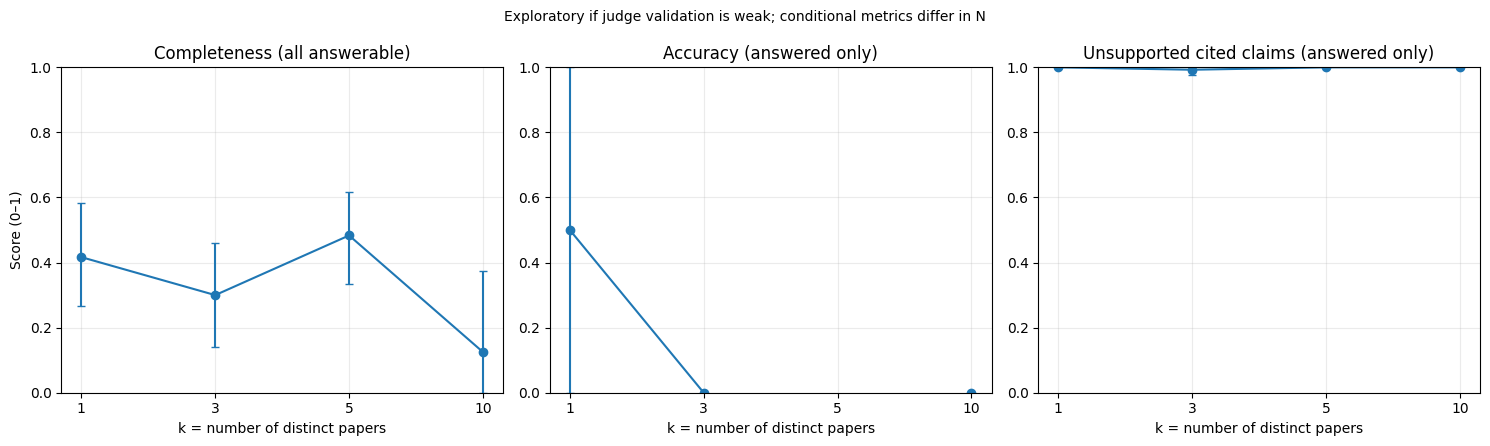

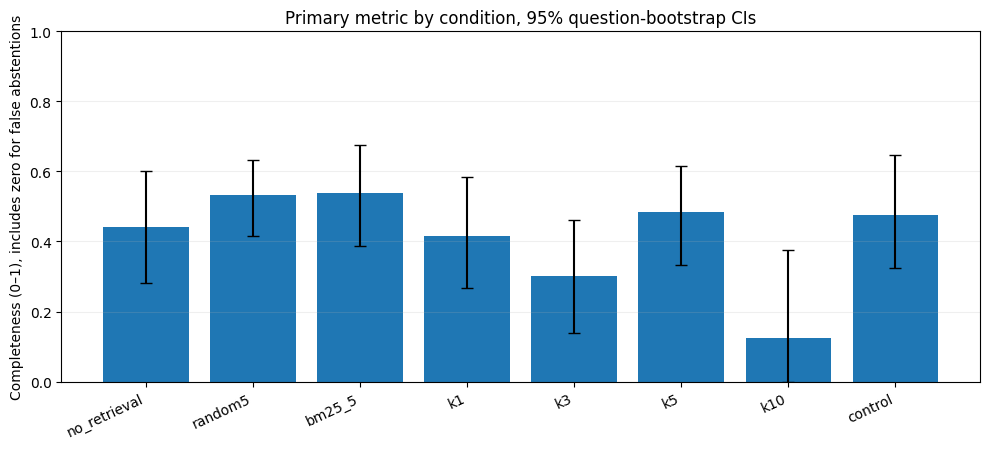

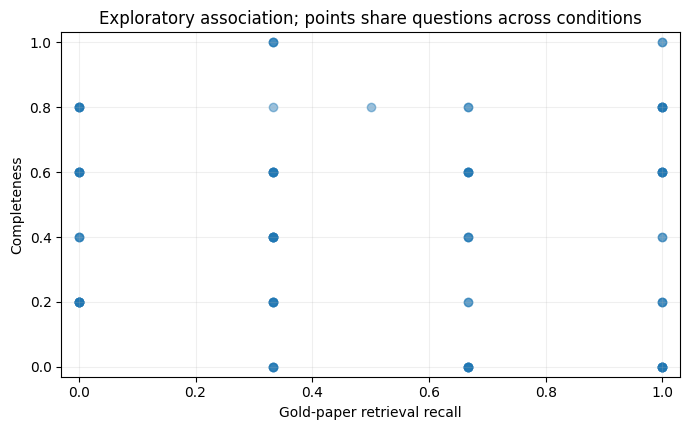

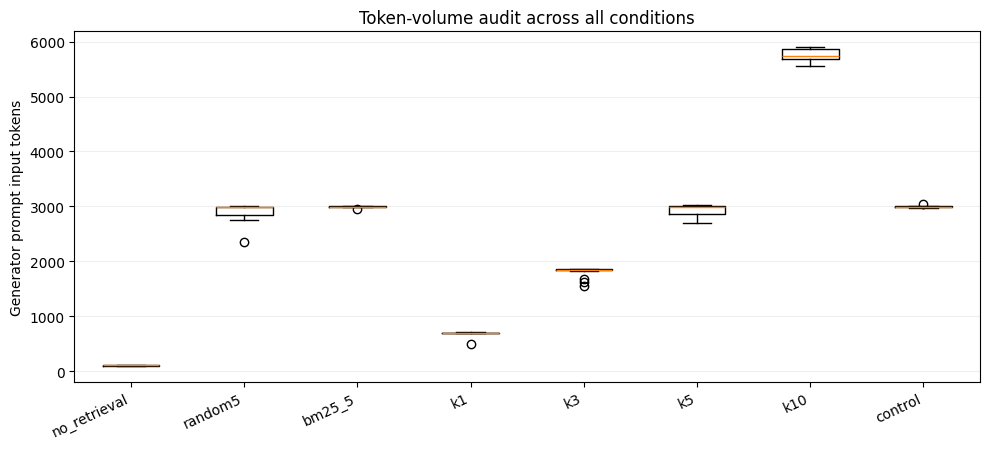

Saved four figures in: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/figures


In [28]:
# Step 24: Create labeled figures from actual results
import os, numpy as np, matplotlib.pyplot as plt
figdir = os.path.join(run_dir,'figures')
os.makedirs(figdir,exist_ok=True)
K=['k1','k3','k5','k10']
KL=['1','3','5','10']

# Figure 1: independent panels; bootstrap 95% CIs for VALID observations.
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
for ax, (metric, name, frame) in zip(axes,[
    ('completeness','Completeness (all answerable)',answerable),
    ('accuracy','Accuracy (answered only)',answered),
    ('hallucination_rate','Unsupported cited claims (answered only)',answered)]):
    means=[];lo=[];hi=[]
    for c in K:
        m,l,h,n = boot_ci(frame.loc[frame.condition==c,metric])
        means.append(m);lo.append(m-l if np.isfinite(m) else np.nan)
        hi.append(h-m if np.isfinite(m) else np.nan)
    ax.errorbar(KL,means,yerr=[lo,hi],marker='o',capsize=3)
    ax.set_title(name)
    ax.set_xlabel('k = number of distinct papers')
    ax.set_ylim(0,1)
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Score (0–1)')
fig.suptitle('Exploratory if judge validation is weak; conditional metrics differ in N',fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(figdir,'fig1_metrics_by_k.png'),dpi=180)
plt.show()

# Figure 2: every condition for the primary measure.
fig,ax=plt.subplots(figsize=(10,4.6))
mu=[];yerr=[[],[]]
for c in ORDER:
    m,l,h,n=boot_ci(answerable.loc[answerable.condition==c,'completeness'])
    mu.append(m);yerr[0].append(m-l);yerr[1].append(h-m)
ax.bar(ORDER,mu,yerr=yerr,capsize=4)
ax.set_ylabel('Completeness (0–1), includes zero for false abstentions')
ax.set_title('Primary metric by condition, 95% question-bootstrap CIs')
ax.grid(axis='y',alpha=0.2)
ax.set_ylim(0,1)
plt.xticks(rotation=25,ha='right')
plt.tight_layout()
fig.savefig(os.path.join(figdir,'fig2_primary_by_condition.png'),dpi=180)
plt.show()

# Figure 3: retrieval recall vs completeness (observational; not causal).
plot_data=answerable.dropna(subset=['gold_paper_recall','completeness'])
fig,ax=plt.subplots(figsize=(7,4.4))
ax.scatter(plot_data['gold_paper_recall'],plot_data['completeness'],alpha=0.45)
ax.set_xlabel('Gold-paper retrieval recall')
ax.set_ylabel('Completeness')
ax.set_title('Exploratory association; points share questions across conditions')
ax.set_xlim(-.03,1.03);ax.set_ylim(-.03,1.03)
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(os.path.join(figdir,'fig3_recall_vs_completeness.png'),dpi=180)
plt.show()

# Figure 4: input tokens (not all runs have the same token count).
fig,ax=plt.subplots(figsize=(10,4.6))
tokens=[answerable.loc[answerable.condition==c,'input_tokens'].dropna().astype(float)
        for c in ORDER]
ax.boxplot(tokens,tick_labels=ORDER,showfliers=True)
ax.set_ylabel('Generator prompt input tokens')
ax.set_title('Token-volume audit across all conditions')
ax.grid(axis='y',alpha=.2)
plt.xticks(rotation=25,ha='right');fig.tight_layout()
fig.savefig(os.path.join(figdir,'fig4_input_tokens.png'),dpi=180)
plt.show()
print('Saved four figures in:',figdir)


## Step 25 — Manual error analysis

The code exports candidates, not verified errors. Manually categorize at least 30 cases (or all, if fewer) using genuine evidence and E1–E7 codes. Your reviewers must record their IDs, plausible causes and anonymized examples.


In [31]:

# STEP 25 — SAFE RESTORE OF EXISTING ERROR ANALYSIS
# Does not overwrite manually classified cases.

import os
import pandas as pd

run_dir = "/content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2"

manual_dir = os.path.join(run_dir, "manual")
results_dir = os.path.join(run_dir, "results")

fixed_path = os.path.join(manual_dir, "error_analysis_FIXED.csv")
original_path = os.path.join(manual_dir, "error_analysis.csv")

# Prefer the previously repaired, manually classified dataset.
if os.path.isfile(fixed_path):
    error_file = fixed_path
elif os.path.isfile(original_path):
    error_file = original_path
else:
    raise FileNotFoundError(
        "Existing manual error analysis was not found."
    )

errors_df = pd.read_csv(error_file, dtype=str).fillna("")

required_columns = [
    "case_id",
    "error_type",
    "possible_cause",
    "anonymised_example",
    "reviewer_id"
]

missing = [
    col for col in required_columns
    if col not in errors_df.columns
]

if missing:
    raise ValueError("Missing columns: " + str(missing))

if errors_df["case_id"].duplicated().any():
    raise RuntimeError("Duplicate case IDs in saved analysis.")

# Fully classified cases only.
complete = (
    errors_df["error_type"].str.strip().ne("")
    & errors_df["possible_cause"].str.strip().ne("")
    & errors_df["anonymised_example"].str.strip().ne("")
    & errors_df["reviewer_id"].str.strip().ne("")
)

classified = errors_df.loc[complete].copy()

print("Source file:", error_file)
print("Total existing cases:", len(errors_df))
print("Fully classified:", len(classified))
print("Required:", 30)

if len(classified) < 30:
    raise RuntimeError(
        "Fewer than 30 complete manual classifications. "
        "Original files have not been changed."
    )

print("\nError type distribution:")
print(classified["error_type"].value_counts().to_string())

# Export a copy of the completed classifications.
# Never overwrite the original manual dataset.
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(
    results_dir,
    "appendix_B_error_analysis_restored.csv"
)

classified.to_csv(output_path, index=False)

print("\nSTEP 25 RESTORE SUCCESSFUL")
print("Original manual file preserved.")
print("Restored appendix:", output_path)


Source file: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/manual/error_analysis_FIXED.csv
Total existing cases: 949
Fully classified: 30
Required: 30

Error type distribution:
error_type
E1_retrieval_miss    30

STEP 25 RESTORE SUCCESSFUL
Original manual file preserved.
Restored appendix: /content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2/results/appendix_B_error_analysis_restored.csv


In [32]:
# Step 25b: Summarize genuinely classified error cases
import os, pandas as pd
reviewed_errors=pd.read_csv(error_file).fillna('')
required_errors=min(30,len(reviewed_errors))
valid_label=reviewed_errors['error_type'].isin(TAXONOMY)
complete_fields=(reviewed_errors['reviewer_id'].astype(str).str.strip().ne('') &
                 reviewed_errors['possible_cause'].astype(str).str.strip().ne('') &
                 reviewed_errors['anonymised_example'].astype(str).str.strip().ne(''))
labelled=reviewed_errors[valid_label & complete_fields]
print('Manually fully classified:',len(labelled),'of',len(reviewed_errors),
      '| required:',required_errors)
if len(labelled)<required_errors:
    print('ERROR ANALYSIS NOT COMPLETE. Fill at least',required_errors,
          'valid error cases with cause, example and reviewer.')
else:
    appendix_b=(labelled.groupby('error_type').agg(
        count=('case_id','size'),
        example=('anonymised_example','first'),
        possible_cause=('possible_cause','first')).reset_index())
    appendix_b['percent']=(100*appendix_b['count']/len(labelled)).round(1)
    appendix_b['definition']=appendix_b.error_type.map(TAXONOMY)
    appendix_b=appendix_b[['error_type','definition','count','percent','example','possible_cause']]
    appendix_b.to_csv(os.path.join(run_dir,'results','appendix_B_error_analysis.csv'),index=False)
    print(appendix_b.to_string(index=False))


Manually fully classified: 30 of 949 | required: 30
       error_type                                              definition  count  percent                                                        example                                                                                                                    possible_cause
E1_retrieval_miss gold evidence required for this claim was not retrieved     30    100.0 Q03 (k1): gold-paper recall 0.33; 2/3 reference papers missed. The retrieved set omitted two of three gold-standard papers; limited top-k or ranking quality may have excluded relevant sources.


## Step 26: Subgroup and efficiency analysis

In [33]:
# Step 26: Subgroups and efficiency
import pandas as pd, numpy as np, os

# No subgroup is a randomized group; results are descriptive, not causal.
subgroup = answerable[answerable.score_status=='ok'].groupby(
    ['question_type','condition']).agg(
    n=('question_id','size'),mean_completeness=('completeness','mean')).reset_index()
subgroup.to_csv(os.path.join(run_dir,'results','subgroup_question_type.csv'),index=False)
print('COMPLETENESS BY QUESTION TYPE:');print(subgroup.round(3).to_string(index=False))

recall_subset=answerable[answerable.score_status=='ok'].copy()
recall_subset['recall_band']=pd.cut(recall_subset.gold_paper_recall,
    bins=[-0.001,0,.999,1.001],labels=['no gold paper','some gold papers','all gold papers'])
recall_summary=recall_subset.groupby(['condition','recall_band'],observed=True).agg(
    n=('question_id','size'),mean_completeness=('completeness','mean')).reset_index()
recall_summary.to_csv(os.path.join(run_dir,'results','subgroup_recall.csv'),index=False)
print('\nCOMPLETENESS BY GOLD RECALL:');print(recall_summary.round(3).to_string(index=False))

successful=answerable[answerable.generation_status=='ok']
efficiency=successful.groupby('condition').agg(
    n=('question_id','size'),input_tokens_median=('input_tokens','median'),
    input_tokens_iqr=('input_tokens',lambda x:x.quantile(.75)-x.quantile(.25)),
    output_tokens_median=('output_tokens','median'),
    latency_median_sec=('latency_sec','median'),
    latency_iqr_sec=('latency_sec',lambda x:x.quantile(.75)-x.quantile(.25)),
).reindex(ORDER)
efficiency.to_csv(os.path.join(run_dir,'results','efficiency.csv'))
print('\nTOKEN AND LATENCY EFFICIENCY:');print(efficiency.round(2).to_string())
print('Interpretation must state that abstentions / answer length affect latency.')


COMPLETENESS BY QUESTION TYPE:
         question_type condition  n  mean_completeness
multi_source_synthesis   control  2                0.0
multi_source_synthesis        k1  2                0.1
multi_source_synthesis       k10  3                0.0
multi_source_synthesis        k3  1                0.0

COMPLETENESS BY GOLD RECALL:
condition      recall_band  n  mean_completeness
  control some gold papers  2                0.0
       k1 some gold papers  2                0.1
      k10  all gold papers  3                0.0
       k3 some gold papers  1                0.0

TOKEN AND LATENCY EFFICIENCY:
               n  input_tokens_median  input_tokens_iqr  output_tokens_median  latency_median_sec  latency_iqr_sec
condition                                                                                                         
no_retrieval  16                105.0              2.50                 265.0               27.59            28.30
random5       16               2986.5      

# Part 8 — Reproducibility package

## Step 27 — Manifest, README, requirements, appendix C template, ZIP

 The two reviewers' initial annotation and agreement are completed according to team attestation. Save the updated `.ipynb` separately before GitHub upload; do not claim that a Git tag or Moodle upload occurred automatically.


In [34]:
# Step 27: Reproducibility package and honest release status
import os, json, subprocess, sys, hashlib, textwrap
from datetime import datetime, timezone

# Environment is pinned to versions *actually installed* in this Colab session.
pip_freeze = subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,
                            text=True,check=True).stdout
keep = {'torch','transformers','sentence-transformers','faiss-cpu','rank-bm25',
        'statsmodels','scipy','numpy','pandas','scikit-learn','accelerate',
        'matplotlib','tqdm','pymupdf','huggingface-hub','tokenizers'}
installed = [l for l in pip_freeze.splitlines()
             if l.split('==')[0].lower().replace('_','-') in keep and '==' in l]
with open(os.path.join(run_dir,'requirements.txt'),'w') as f:
    f.write('\n'.join(sorted(installed))+'\n')

# Metadata can be shared more freely than full paper texts; check licence per item.
columns = [c for c in ('paper_id','title','arxiv_id','url') if c in final_papers_df.columns]
if 'paper_id' in columns:
    final_papers_df[columns].to_csv(os.path.join(run_dir,'data','corpus_metadata.csv'),index=False)

_data_note = f'''# Data access, provenance and licences

This experiment is designed to use a FROZEN, VERIFIED benchmark, not the
team-reviewed benchmark v2 with seven POST-FREEZE key-point wording revisions; those revisions must be documented and authorized. Expected input files (local, not
necessarily redistributable):

- `final_papers.json` — SHA256 `{freeze['papers_sha256']}`
- `final_chunks.json` — SHA256 `{freeze['chunks_sha256']}`
- `final_faiss.index` — SHA256 `{freeze['original_index_sha256']}`
- `benchmark_questions_v2.json` — SHA256 `{freeze['benchmark_sha256']}`
- `selected_faiss.index` — stored in Assignment 4 results folder, SHA256
  `{CONFIG['selected_index_sha256']}`

The corpus includes 50 arXiv papers, preprocessed into 863 chunks. A list of
paper identifiers is in `corpus_metadata.csv`. arXiv open access does NOT
necessarily mean rights to redistribute all full texts or derived copies;
check individual licences before publishing datasets. Obtain the EXACT
frozen dataset from the owners with permission, or provide a reproducible
collection+preprocessing script that recreates the exact hashes.

The 25-question benchmark and manual labels are research artifacts.
Sharing may require team approval; do not publish without permission.
If these files are not accessible to the replicator, a full independent
reproduction has NOT been achieved: report this limitation explicitly.
'''
with open(os.path.join(run_dir,'data','README.md'),'w') as f:
    f.write(_data_note)

readme = f'''# Retrieval Breadth in Multi-Source Scientific RAG — Assignment 4

**Status:** This folder contains program-generated artifacts, not proof of
Moodle submission, successful full run, manual validation or a GitHub release.

## Research design

Same 20 **untouched test questions** for eight conditions: closed-book
(no_retrieval), RANDOM-5, BM25-5, dense k = 1, 3, 5, 10, and a five-passage
single-paper control formed from five disjoint spans of the top-ranked
paper in the frozen corpus. Five additional questions form the DEV set. Primary
metric: key-point completeness. Secondary: reference correctness, cited-
passage support, abstention, gold-paper recall, tokens and latency.

### Control implementation\n\nThe top-ranked source paper is split into non-overlapping 550-token (or shorter if necessary) windows, ranked using the selected dense embedder. Five windows are selected without modifying the original frozen corpus or FAISS indexes. Actual window text and source-token ranges are stored in each generation log record to verify citations. Prompt-token matching is measured and reported, not assumed. This is a documented implementation clarification and requires instructor review if it differs from the interpretation of the signed protocol.\n\n## Important measurement limitations

- Accuracy and unsupported-claim rates are conditional on non-abstaining
  answers. Compare alongside n_answered and false abstention.
- For closed-book k=0, no citations exist. Its rate of **claims unsupported
  by supplied passages** is 1 for any answered claim BY DEFINITION. H5 must
  not be treated as evidence that retrieval causally reduces hallucinations.
- Removing the citation instruction in the ablation changes citation
  compliance by definition; do not equate that change with factual error.
- Mark automatic outputs EXPLORATORY if judge-versus-human kappa < 0.40.
- Every skipped/failed run is retained in raw logs. Never delete it.

## What you need

1. Colab GPU access, Hugging Face model download access, and exact frozen
   input artifacts in the private `RAG_Assignment3` folder; see `data/README.md`.
2. `Assignment4_complete_experiment_BENCHMARK_V2.ipynb` and all results/selected index
   from this release. Original benchmark must match the pinned hash.
3. Complete human-review sheets, with TWO independent reviewers and a
   documented consensus; see `manual/` after Step 20.

## Original run (not a reproduction)

Use `Assignment4_complete_experiment_BENCHMARK_V2.ipynb`, T4 GPU.

1. Step 1: check `base_dir` and `run_dir`. Start with truthfully blank confirmation fields.
2. Steps 2–14: corpus remains frozen when present; DEV alone decides model / prompt.
3. Before Step 15: inspect the real Moodle receipt timestamp, verify all 100
   benchmark key points, and document the post-freeze v2 content revision
   with the instructor. Only then update Step 1 confirmation fields and rerun
   Step 1 if necessary.
4. Step 15: first access to TEST; 160 logged main runs. Step 16 has 16 ablations.
5. Steps 18–20: judge scoring and blind human review sheets.
6. Two people independently fill their sheets; enter each review and resolved
   consensus in the master sheets. Do not replace existing human annotations.
7. Run Steps 21–25. Categorize at least 30 actual errors (or all if fewer),
   then rerun Step 25b and Step 27. Do not claim final submission readiness
   until all manual validation and an independent reproduction are done.

If any experiment fails, keep the failure log and explain it in the report.

## Independent clean reproduction

On a separate runtime, use the SAME frozen source dataset and the original
run's released `final_config.json`, `selected_faiss.index` and
`protocol_freeze.json`. Set a DIFFERENT output directory:

```python
import os
os.environ['RAG_A4_REPRODUCE'] = '1'
os.environ['RAG_A4_CONFIG_SOURCE'] = '/content/drive/MyDrive/RAG_Assignment4_BENCHMARK_V2'
os.environ['RAG_A4_RUN_DIR'] = '/content/drive/MyDrive/RAG_Assignment4_REPRO'
os.environ['RAG_A3_DATA_DIR'] = '/content/drive/MyDrive/RAG_Assignment3'
```

Execute all notebook cells in order: Steps 12–13 automatically SKIP
DEV model/prompt selection, Step 14 loads the archived config and selected index,
and Step 15 regenerates the 160 raw TEST runs. Then recompute Step 19 scores and
compare `results/test_answer_scores.csv` and the main table metric columns.
For full human-validated main results, approved copies of manual consensus
sheets must be available; machine-only scores must not be represented as
human validated. Document the second person's **actual** system, commands,
differences and failures in Appendix C (template in this folder).

## Output layout

- `logs/`: every generation and raw judge responses (JSONL)
- `results/`: computed tables, statistics, validation record, scorer config
- `manual/`: independent reviews, master labels, error classifications
- `figures/`: images for the report
- `protocol_freeze.json` / `final_config.json`: frozen decisions
- `selected_faiss.index`: exact final retrieval index
- `environment.json`, `environment_pip_freeze.txt`, `requirements.txt`
- `RESULTS_MANIFEST.json`: SHA256 checksums of the artifact package

## Attribution / licences

MIT licence applies only to original project code, subject to the team
confirming they own the code rights. It does NOT license third-party papers,
model weights, datasets or Hugging Face model licences.

## Notebook inclusion

The Colab notebook itself is not automatically copied from the notebook UI into this folder.
Add `Assignment4_complete_experiment_BENCHMARK_V2.ipynb` to GitHub separately.

## Protocol discrepancy

The signed Appendix A names `benchmark_questions_v2.json`, but the seven
key-point wording revisions were made after the original freeze. Record changes and approval;
record both filenames and the actual SHA256. This package cannot itself
prove approval or the timestamp of the Moodle protocol upload.

## GitHub/GitLab release

After all files are audited and all owners approve publication, commit the
approved artifacts (do not commit private full texts/tokens) and create the
required release with tag **`assignment-4`**. This notebook does NOT claim
to create a Git tag or to upload anything.

```bash
git tag -a assignment-4 -m "Assignment 4 validated experiment"
git push origin assignment-4
```

For every claim in the report cite a local log/CSV and, ideally, its SHA256
from `RESULTS_MANIFEST.json`. Do not copy pilot numbers into the final tables.
'''
with open(os.path.join(run_dir,'README.md'),'w') as f:
    f.write(readme)

# The originally provided notebook used an MIT grant; preserve that choice
# for *original code only*, subject to the authors' approval.
license_text = '''MIT License

Copyright (c) 2026 Reviewer A, Project contributor, Reviewer B

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
'''
with open(os.path.join(run_dir,'LICENSE'),'w') as f:
    f.write(license_text)

appendix_c = '''# Appendix C — Reproduction Test Record (BLANK)

This is a template. Have another member of the team (or a classmate for
individual work) complete it after a REAL clean reproduction.

- Person who reproduced results: ___________________
- Date and timezone: _______________________________
- Machine / GPU / OS / Python: ______________________
- Repository commit and release tag: _______________
- Raw data / benchmark SHA256 matched? _____________
- Commands and notebook steps executed: ____________
- Main results table reproduced (Yes/Partly/No): ___
- Exact metric differences and explanations: _______
- Errors and README changes: _______________________
- Evidence (log paths or screenshots): _____________
'''
with open(os.path.join(run_dir,'Appendix_C_REPRODUCTION_TEMPLATE.md'),'w') as f:
    f.write(appendix_c)

status = dict(created_utc=datetime.now(timezone.utc).isoformat(),
              numerical_results_reviewed=bool(submission_ready),
              validation_complete=bool(validation_status.get('complete',False)),
              judge_exploratory=bool(validation_status.get('judge_exploratory',True)),
              all_planned_generations_logged=len(load_jsonl(results_path))==160,
              all_ablation_runs_logged=len(load_jsonl(abl_path))==16,
              error_analysis_complete=bool('labelled' in globals() and len(labelled)>=min(30,len(reviewed_errors))),
              full_submission_ready=False,  # Real independent reproduction and report still pending
              github_release_tag_verified=False,
              independent_reproduction_verified=False,
              moodle_upload_timestamp_self_reported=bool(MOODLE_UPLOAD_TIME and not REPRODUCTION_MODE),
              moodle_receipt_independently_verified=False,
              keypoints_verified_user_claim=bool(KEYPOINTS_VERIFIED and not REPRODUCTION_MODE))
with open(os.path.join(run_dir,'OUTPUT_STATUS.json'),'w') as f:
    json.dump(status,f,indent=2)

# Generate MANIFEST last, avoiding circular self-hashing.
manifest = dict(generated_utc=datetime.now(timezone.utc).isoformat(),files={})
for root,_,files in os.walk(run_dir):
    for file in files:
        path=os.path.join(root,file)
        if file == 'RESULTS_MANIFEST.json':
            continue
        # Google Workspace link stubs are not readable binary files in Colab Drive.
        if file.lower().endswith(('.gsheet', '.gdoc', '.gslides')):
            print('SKIPPED Google Workspace shortcut:', os.path.relpath(path, run_dir))
            continue
        relative = os.path.relpath(path, run_dir)
        try:
            manifest['files'][relative] = dict(
                sha256=file_sha256(path), bytes=os.path.getsize(path)
            )
        except OSError as exc:
            raise OSError(f'Cannot hash required file {relative}: {exc}') from exc
with open(os.path.join(run_dir,'RESULTS_MANIFEST.json'),'w') as f:
    json.dump(manifest,f,indent=2)
print('Generated README, data access instructions, requirements, licence, '
      'Appendix C template, status and hash manifest.')
print('Status:',json.dumps(status,indent=2))
print('IMPORTANT: source dataset rights, Moodle receipt, actual model runs, '
      'human reviews, Git tag and independent reproduction remain real-world tasks.')


# This is a ZIP of locally generated files, not an automatically verified submission.
# Do not redistribute third-party paper contents or secrets.
import shutil
import zipfile
label = ('RESULTS_REVIEW_REQUIRED' if submission_ready and
         'labelled' in globals() and len(labelled)>=min(30,len(reviewed_errors))
         else 'DRAFT_REVIEW_REQUIRED')
archive_base = '/content/RAG_Assignment4_' + label
# Zip only files already verified by the manifest. This also excludes Google
# Workspace shortcut stubs, which cannot be read as binary files.
with zipfile.ZipFile(archive_base + '.zip', 'w', compression=zipfile.ZIP_DEFLATED, allowZip64=True) as archive:
    for relative in sorted(manifest['files']):
        full_path = os.path.join(run_dir, relative)
        archive.write(full_path, arcname=relative)
    archive.write(os.path.join(run_dir, 'RESULTS_MANIFEST.json'), arcname='RESULTS_MANIFEST.json')
print('Archive saved:', archive_base + '.zip')
print('Copy the reviewed .ipynb into the Git repository yourself; Colab does not automatically include it.')
try:
    from google.colab import files
    files.download(archive_base + '.zip')
except ImportError:
    pass


SKIPPED Google Workspace shortcut: manual/blind_claims_reviewer1.gsheet
SKIPPED Google Workspace shortcut: manual/blind_keypoints_reviewer1.gsheet
SKIPPED Google Workspace shortcut: AI_QUALITY_ISSUES_VERIFIED/Possible_nonfactual_extraction_cases (1).gsheet
SKIPPED Google Workspace shortcut: AI_QUALITY_ISSUES_VERIFIED/Keypoint_8_directly_inspected_judge_errors.gsheet
SKIPPED Google Workspace shortcut: AI_QUALITY_ISSUES_VERIFIED/Possible_nonfactual_extraction_cases.gsheet
Generated README, data access instructions, requirements, licence, Appendix C template, status and hash manifest.
Status: {
  "created_utc": "2026-11-08T13:42:42.815887+00:00",
  "numerical_results_reviewed": false,
  "validation_complete": false,
  "judge_exploratory": true,
  "all_planned_generations_logged": true,
  "all_ablation_runs_logged": true,
  "error_analysis_complete": true,
  "full_submission_ready": false,
  "github_release_tag_verified": false,
  "independent_reproduction_verified": false,
  "moodle_uploa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>